<a href="https://colab.research.google.com/github/snkhader22/Deep-Learning-Project/blob/main/DL2.final_result.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error



In [5]:
df = pd.read_csv('/content/train.csv')

In [6]:
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (188533, 13)

First 5 rows:


,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            188533 non-null  int64 
 1   brand         188533 non-null  object
 2   model         188533 non-null  object
 3   model_year    188533 non-null  int64 
 4   milage        188533 non-null  int64 
 5   fuel_type     183450 non-null  object
 6   engine        188533 non-null  object
 7   transmission  188533 non-null  object
 8   ext_col       188533 non-null  object
 9   int_col       188533 non-null  object
 10  accident      186081 non-null  object
 11  clean_title   167114 non-null  object
 12  price         188533 non-null  int64 
dtypes: int64(4), object(9)
memory usage: 18.7+ MB

Missing values:
id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        5083
engine              0


In [7]:
# Identify numerical and categorical columns

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
['id', 'model_year', 'milage', 'price']

Categorical Columns:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


In [8]:
# Statistical summary of numerical columns

display(df.describe())

,id,model_year,milage,price
count,188533.000000,188533.000000,188533.000000,1.885330e+05
mean,94266.000000,2015.829998,65705.295174,4.387802e+04
std,54424.933488,5.660967,49798.158076,7.881952e+04
min,0.000000,1974.000000,100.000000,2.000000e+03
25%,47133.000000,2013.000000,24115.000000,1.700000e+04
50%,94266.000000,2017.000000,57785.000000,3.082500e+04
75%,141399.000000,2020.000000,95400.000000,4.990000e+04
max,188532.000000,2024.000000,405000.000000,2.954083e+06


Price Statistics:
count    1.885330e+05
mean     4.387802e+04
std      7.881952e+04
min      2.000000e+03
25%      1.700000e+04
50%      3.082500e+04
75%      4.990000e+04
max      2.954083e+06
Name: price, dtype: float64


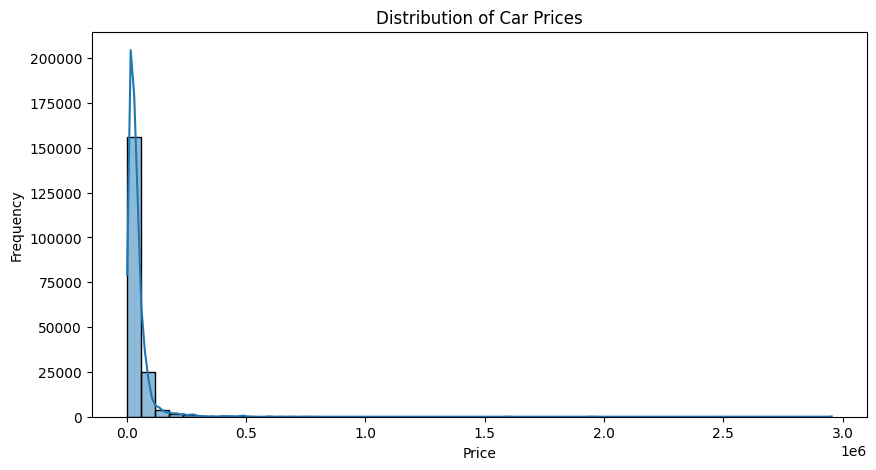

In [9]:
# Analyze target variable

print("Price Statistics:")
print(df['price'].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df['price'], bins=50, kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

In [10]:
# Number of unique values in each categorical column

for col in categorical_cols:
    print(col, ":", df[col].nunique())

brand : 57
model : 1897
fuel_type : 7
engine : 1117
transmission : 52
ext_col : 319
int_col : 156
accident : 2
clean_title : 1


In [11]:
# Create a copy of the dataset
df = df.copy()

# Remove unnecessary ID column
df = df.drop(columns=['id'])

print("ID column removed successfully!")
print("New dataset shape:", df.shape)

ID column removed successfully!
New dataset shape: (188533, 12)


In [12]:
# Get categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# Remove unnecessary whitespace
for col in categorical_cols:
    df[col] = df[col].str.strip()

# Convert empty strings into missing values
df[categorical_cols] = df[categorical_cols].replace(r'^\s*$', np.nan, regex=True)

print("Categorical values cleaned successfully!")

Categorical values cleaned successfully!


In [13]:
# Fill missing categorical values
for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")

print("Missing categorical values handled!")

Missing categorical values handled!


In [14]:
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

Missing values after cleaning:
brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64

Dataset shape:
(188533, 12)

First 5 rows:


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,MINI,Cooper S Base,2007,213000,Gasoline,172.0HP 1.6L 4 Cylinder Engine Gasoline Fuel,A/T,Yellow,Gray,None reported,Yes,4200
1,Lincoln,LS V8,2002,143250,Gasoline,252.0HP 3.9L 8 Cylinder Engine Gasoline Fuel,A/T,Silver,Beige,At least 1 accident or damage reported,Yes,4999
2,Chevrolet,Silverado 2500 LT,2002,136731,E85 Flex Fuel,320.0HP 5.3L 8 Cylinder Engine Flex Fuel Capab...,A/T,Blue,Gray,None reported,Yes,13900
3,Genesis,G90 5.0 Ultimate,2017,19500,Gasoline,420.0HP 5.0L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,45000
4,Mercedes-Benz,Metris Base,2021,7388,Gasoline,208.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,7-Speed A/T,Black,Beige,None reported,Yes,97500


In [15]:
# Separate features and target

X = df.drop(columns=['price'])
y = df['price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Features shape: (188533, 11)
Target shape: (188533,)

Features:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


In [16]:
# First split: 70% training, 30% temporary

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Second split: 15% validation, 15% testing

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (131973, 11)
Validation set: (28280, 11)
Testing set: (28280, 11)


In [17]:
# Calculate dataset percentages

total = len(df)

print("Training:", round(len(X_train) / total * 100, 2), "%")
print("Validation:", round(len(X_val) / total * 100, 2), "%")
print("Testing:", round(len(X_test) / total * 100, 2), "%")

Training: 70.0 %
Validation: 15.0 %
Testing: 15.0 %


In [18]:
#Apply One-Hot Encoding

from sklearn.preprocessing import OneHotEncoder

# Identify categorical features
categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Categorical features:")
print(categorical_features)

# Create the encoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    max_categories=50,
    sparse_output=False
)

# Fit on training data and transform all datasets
X_train_cat = encoder.fit_transform(
    X_train[categorical_features]
)

X_val_cat = encoder.transform(
    X_val[categorical_features]
)

X_test_cat = encoder.transform(
    X_test[categorical_features]
)

# Convert to float32
X_train_cat = X_train_cat.astype(np.float32)
X_val_cat = X_val_cat.astype(np.float32)
X_test_cat = X_test_cat.astype(np.float32)

print("\nEncoding completed successfully!")

print("Training categorical shape:", X_train_cat.shape)
print("Validation categorical shape:", X_val_cat.shape)
print("Testing categorical shape:", X_test_cat.shape)

print("\nTotal encoded features:", X_train_cat.shape[1])

Categorical features:
['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']

Encoding completed successfully!
Training categorical shape: (131973, 313)
Validation categorical shape: (28280, 313)
Testing categorical shape: (28280, 313)

Total encoded features: 313


In [19]:
#Import and create the scaler

from sklearn.preprocessing import StandardScaler

# Identify numerical features
numerical_features = ['model_year', 'milage']

# Create the scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_num = scaler.fit_transform(
    X_train[numerical_features]
)

# Transform validation and testing data
X_val_num = scaler.transform(
    X_val[numerical_features]
)

X_test_num = scaler.transform(
    X_test[numerical_features]
)

print("Numerical scaling completed!")

print("Training numerical shape:", X_train_num.shape)
print("Validation numerical shape:", X_val_num.shape)
print("Testing numerical shape:", X_test_num.shape)

Numerical scaling completed!
Training numerical shape: (131973, 2)
Validation numerical shape: (28280, 2)
Testing numerical shape: (28280, 2)


In [20]:
print("Training numerical means:")
print(X_train_num.mean(axis=0))

print("\nTraining numerical standard deviations:")
print(X_train_num.std(axis=0))

Training numerical means:
[7.73228657e-15 7.90371315e-17]

Training numerical standard deviations:
[1. 1.]


In [21]:
# Combine numerical and categorical features

X_train_final = np.concatenate(
    [X_train_num, X_train_cat], axis=1
)

X_val_final = np.concatenate(
    [X_val_num, X_val_cat], axis=1
)

X_test_final = np.concatenate(
    [X_test_num, X_test_cat], axis=1
)

print("Final feature shapes:")

print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Testing:", X_test_final.shape)

Final feature shapes:
Training: (131973, 315)
Validation: (28280, 315)
Testing: (28280, 315)


In [22]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create target scaler
target_scaler = StandardScaler()

# Fit on training prices only
y_train_scaled = target_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

# Transform validation and testing prices
y_val_scaled = target_scaler.transform(
    y_val.to_numpy().reshape(-1, 1)
)

y_test_scaled = target_scaler.transform(
    y_test.to_numpy().reshape(-1, 1)
)

print("Target scaling completed!")
print("Training target mean:", y_train_scaled.mean())
print("Training target std:", y_train_scaled.std())

Target scaling completed!
Training target mean: 9.475841383751042e-18
Training target std: 1.0


In [23]:
# Convert features to float32
X_train_final = X_train_final.astype(np.float32)
X_val_final = X_val_final.astype(np.float32)
X_test_final = X_test_final.astype(np.float32)

# Convert features to PyTorch tensors
X_train_tensor = torch.tensor(X_train_final, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_final, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_final, dtype=torch.float32)

# Convert targets to PyTorch tensors
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)

print("PyTorch tensors created successfully!")

PyTorch tensors created successfully!


In [24]:
print("Training features:", X_train_tensor.shape)
print("Training target:", y_train_tensor.shape)

print("Validation features:", X_val_tensor.shape)
print("Validation target:", y_val_tensor.shape)

print("Testing features:", X_test_tensor.shape)
print("Testing target:", y_test_tensor.shape)

Training features: torch.Size([131973, 315])
Training target: torch.Size([131973, 1])
Validation features: torch.Size([28280, 315])
Validation target: torch.Size([28280, 1])
Testing features: torch.Size([28280, 315])
Testing target: torch.Size([28280, 1])


In [25]:
# Define Linear Regression model

class LinearRegressionModel(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.linear = nn.Linear(input_size, 1)

    def forward(self, x):
        return self.linear(x)


# Create the model
linear_model = LinearRegressionModel(input_size=315)

print(linear_model)

LinearRegressionModel(
  (linear): Linear(in_features=315, out_features=1, bias=True)
)


In [26]:
from torch.utils.data import TensorDataset, DataLoader

# Create training dataset
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Create DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
optimizer = optim.Adam(
    linear_model.parameters(),
    lr=0.01
)

# Number of epochs
epochs = 30

print("Training setup completed!")

Training setup completed!


In [27]:
# Store training and validation losses
linear_train_losses = []
linear_val_losses = []

for epoch in range(epochs):

    # Training mode
    linear_model.train()

    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        # Forward pass
        predictions = linear_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation mode
    linear_model.eval()

    with torch.no_grad():

        val_predictions = linear_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    linear_train_losses.append(train_loss)
    linear_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Linear Regression training completed!")

Epoch [1/30], Train Loss: 0.8932, Val Loss: 0.7047
Epoch [2/30], Train Loss: 0.8887, Val Loss: 0.7031
Epoch [3/30], Train Loss: 0.8884, Val Loss: 0.7118
Epoch [4/30], Train Loss: 0.8888, Val Loss: 0.7081
Epoch [5/30], Train Loss: 0.8881, Val Loss: 0.7163
Epoch [6/30], Train Loss: 0.8890, Val Loss: 0.7043
Epoch [7/30], Train Loss: 0.8881, Val Loss: 0.7054
Epoch [8/30], Train Loss: 0.8889, Val Loss: 0.7051
Epoch [9/30], Train Loss: 0.8890, Val Loss: 0.7053
Epoch [10/30], Train Loss: 0.8875, Val Loss: 0.7176
Epoch [11/30], Train Loss: 0.8889, Val Loss: 0.7160
Epoch [12/30], Train Loss: 0.8885, Val Loss: 0.7052
Epoch [13/30], Train Loss: 0.8874, Val Loss: 0.7067
Epoch [14/30], Train Loss: 0.8883, Val Loss: 0.7065
Epoch [15/30], Train Loss: 0.8888, Val Loss: 0.7085
Epoch [16/30], Train Loss: 0.8882, Val Loss: 0.7124
Epoch [17/30], Train Loss: 0.8882, Val Loss: 0.7125
Epoch [18/30], Train Loss: 0.8891, Val Loss: 0.7092
Epoch [19/30], Train Loss: 0.8882, Val Loss: 0.7137
Epoch [20/30], Train 

In [28]:
# Convert predictions back to original price scale

linear_model.eval()

with torch.no_grad():

    train_pred_scaled = linear_model(X_train_tensor).numpy()
    val_pred_scaled = linear_model(X_val_tensor).numpy()

    train_predictions = target_scaler.inverse_transform(
        train_pred_scaled
    )

    val_predictions = target_scaler.inverse_transform(
        val_pred_scaled
    )

# Calculate MSE
linear_train_mse = mean_squared_error(
    y_train,
    train_predictions
)

linear_val_mse = mean_squared_error(
    y_val,
    val_predictions
)

print("Linear Regression Results")
print("--------------------------")
print("Training MSE:", linear_train_mse)
print("Validation MSE:", linear_val_mse)

Linear Regression Results
--------------------------
Training MSE: 5837007360.0
Validation MSE: 4664658944.0


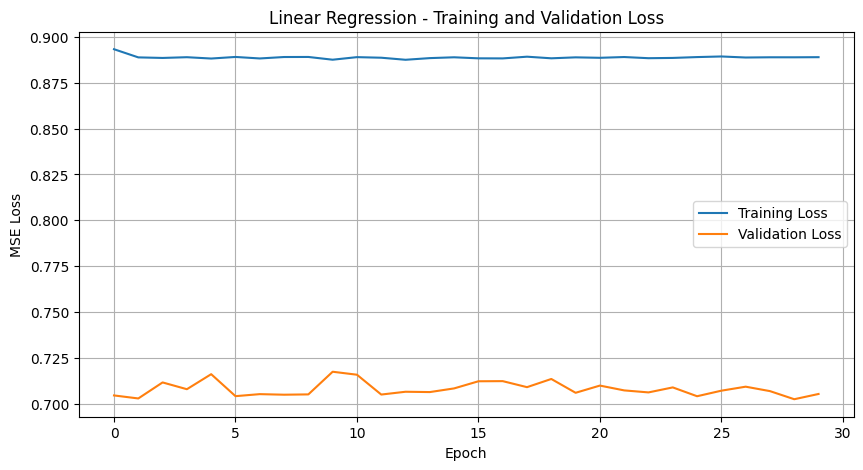

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    linear_train_losses,
    label="Training Loss"
)

plt.plot(
    linear_val_losses,
    label="Validation Loss"
)

plt.title("Linear Regression - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.show()

In [30]:
# Define Deep Neural Network

class DeepNeuralNetwork(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model
dnn_model = DeepNeuralNetwork(input_size=315)

print(dnn_model)

DeepNeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [31]:
# Create DataLoader for DNN

dnn_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
dnn_optimizer = optim.Adam(
    dnn_model.parameters(),
    lr=0.001
)

# Number of epochs
epochs = 30

print("DNN training setup completed!")

DNN training setup completed!


In [32]:
# Store training and validation losses

dnn_train_losses = []
dnn_val_losses = []

for epoch in range(epochs):

    dnn_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = dnn_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        dnn_optimizer.zero_grad()

        loss.backward()

        dnn_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    dnn_model.eval()

    with torch.no_grad():

        val_predictions = dnn_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    dnn_train_losses.append(train_loss)
    dnn_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("DNN training completed!")

Epoch [1/30], Train Loss: 0.8822, Val Loss: 0.6865
Epoch [2/30], Train Loss: 0.8655, Val Loss: 0.6871
Epoch [3/30], Train Loss: 0.8615, Val Loss: 0.6881
Epoch [4/30], Train Loss: 0.8585, Val Loss: 0.6844
Epoch [5/30], Train Loss: 0.8542, Val Loss: 0.6858
Epoch [6/30], Train Loss: 0.8501, Val Loss: 0.6863
Epoch [7/30], Train Loss: 0.8441, Val Loss: 0.6921
Epoch [8/30], Train Loss: 0.8372, Val Loss: 0.6906
Epoch [9/30], Train Loss: 0.8255, Val Loss: 0.6963
Epoch [10/30], Train Loss: 0.8145, Val Loss: 0.6946
Epoch [11/30], Train Loss: 0.7966, Val Loss: 0.6945
Epoch [12/30], Train Loss: 0.7776, Val Loss: 0.7087
Epoch [13/30], Train Loss: 0.7454, Val Loss: 0.7199
Epoch [14/30], Train Loss: 0.7270, Val Loss: 0.7218
Epoch [15/30], Train Loss: 0.7034, Val Loss: 0.7332
Epoch [16/30], Train Loss: 0.7006, Val Loss: 0.7377
Epoch [17/30], Train Loss: 0.6901, Val Loss: 0.7738
Epoch [18/30], Train Loss: 0.6813, Val Loss: 0.7591
Epoch [19/30], Train Loss: 0.6641, Val Loss: 0.7214
Epoch [20/30], Train 

In [33]:
# Evaluate DNN

dnn_model.eval()

with torch.no_grad():

    train_pred_scaled = dnn_model(X_train_tensor).numpy()

    val_pred_scaled = dnn_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    train_predictions = target_scaler.inverse_transform(
        train_pred_scaled
    )

    val_predictions = target_scaler.inverse_transform(
        val_pred_scaled
    )

# Calculate MSE
dnn_train_mse = mean_squared_error(
    y_train,
    train_predictions
)

dnn_val_mse = mean_squared_error(
    y_val,
    val_predictions
)

print("Deep Neural Network Results")
print("---------------------------")

print("Training MSE:", dnn_train_mse)

print("Validation MSE:", dnn_val_mse)

Deep Neural Network Results
---------------------------
Training MSE: 3831175680.0
Validation MSE: 5036454912.0


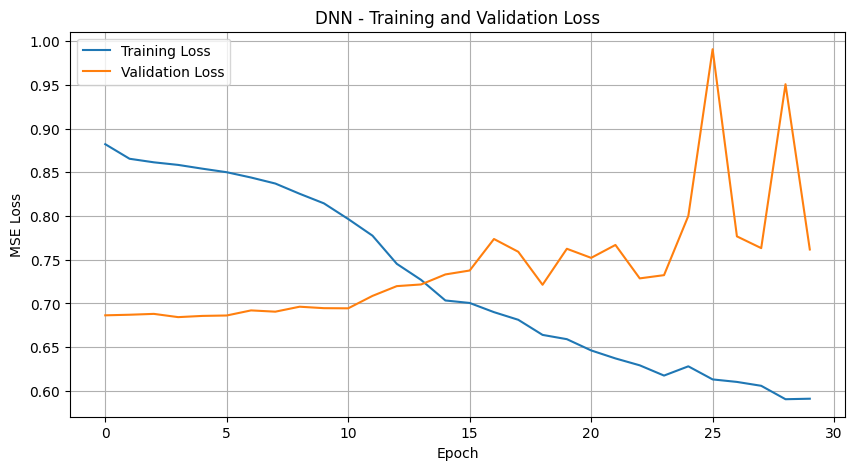

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(
    dnn_train_losses,
    label="Training Loss"
)

plt.plot(
    dnn_val_losses,
    label="Validation Loss"
)

plt.title("DNN - Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("MSE Loss")

plt.legend()

plt.grid(True)

plt.show()

In [35]:
# Compare baseline models

comparison = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Deep Neural Network"
    ],

    "Training MSE": [
        linear_train_mse,
        dnn_train_mse
    ],

    "Validation MSE": [
        linear_val_mse,
        dnn_val_mse
    ]

})

display(comparison)

,Model,Training MSE,Validation MSE
0,Linear Regression,5.837007e+09,4.664659e+09
1,Deep Neural Network,3.831176e+09,5.036455e+09


In [36]:
# EXPERIMENT 1 - LEARNING RATE 0.00001

# Create a fresh DNN model
exp1_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.00001
exp1_optimizer = optim.Adam(
    exp1_model.parameters(),
    lr=0.00001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp1_train_losses = []
exp1_val_losses = []

print("Experiment 1 setup completed!")

Experiment 1 setup completed!


In [37]:
# EXPERIMENT 1 - TRAIN MODEL

for epoch in range(30):

    # Set model to training mode
    exp1_model.train()

    total_train_loss = 0

    # Loop through training batches
    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp1_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp1_optimizer.zero_grad()

        loss.backward()

        exp1_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp1_model.eval()

    with torch.no_grad():

        val_predictions = exp1_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp1_train_losses.append(train_loss)
    exp1_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 1 completed!")

Epoch [1/30], Train Loss: 0.9996, Val Loss: 0.8065
Epoch [2/30], Train Loss: 0.9756, Val Loss: 0.7736
Epoch [3/30], Train Loss: 0.9399, Val Loss: 0.7398
Epoch [4/30], Train Loss: 0.9163, Val Loss: 0.7243
Epoch [5/30], Train Loss: 0.9054, Val Loss: 0.7167
Epoch [6/30], Train Loss: 0.8989, Val Loss: 0.7115
Epoch [7/30], Train Loss: 0.8940, Val Loss: 0.7075
Epoch [8/30], Train Loss: 0.8900, Val Loss: 0.7041
Epoch [9/30], Train Loss: 0.8867, Val Loss: 0.7014
Epoch [10/30], Train Loss: 0.8839, Val Loss: 0.6991
Epoch [11/30], Train Loss: 0.8815, Val Loss: 0.6970
Epoch [12/30], Train Loss: 0.8794, Val Loss: 0.6952
Epoch [13/30], Train Loss: 0.8775, Val Loss: 0.6937
Epoch [14/30], Train Loss: 0.8759, Val Loss: 0.6924
Epoch [15/30], Train Loss: 0.8744, Val Loss: 0.6912
Epoch [16/30], Train Loss: 0.8732, Val Loss: 0.6902
Epoch [17/30], Train Loss: 0.8720, Val Loss: 0.6893
Epoch [18/30], Train Loss: 0.8710, Val Loss: 0.6885
Epoch [19/30], Train Loss: 0.8700, Val Loss: 0.6878
Epoch [20/30], Train 

In [38]:
# EXPERIMENT 1 - EVALUATE MODEL

exp1_model.eval()

with torch.no_grad():

    exp1_val_scaled = exp1_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp1_val_predictions = target_scaler.inverse_transform(
        exp1_val_scaled
    )

# Calculate validation MSE
exp1_val_mse = mean_squared_error(
    y_val,
    exp1_val_predictions
)

print("Experiment 1 Validation MSE:", exp1_val_mse)

Experiment 1 Validation MSE: 4519097344.0


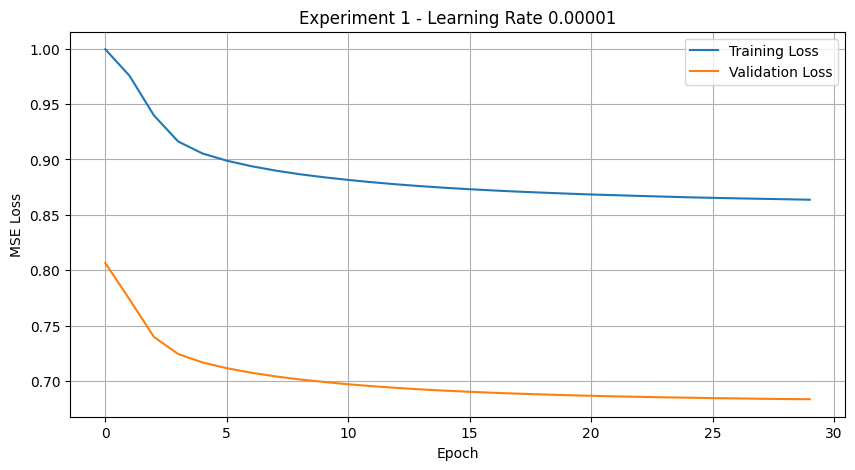

In [39]:
# EXPERIMENT 1 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp1_train_losses,
    label="Training Loss"
)

plt.plot(
    exp1_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 1 - Learning Rate 0.00001")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [40]:
# EXPERIMENT 2 - LEARNING RATE 0.0001

# Create a fresh DNN model
exp2_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.0001
exp2_optimizer = optim.Adam(
    exp2_model.parameters(),
    lr=0.0001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp2_train_losses = []
exp2_val_losses = []

print("Experiment 2 setup completed!")

Experiment 2 setup completed!


In [41]:
# EXPERIMENT 2 - TRAIN MODEL

for epoch in range(30):

    exp2_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp2_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp2_optimizer.zero_grad()

        loss.backward()

        exp2_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp2_model.eval()

    with torch.no_grad():

        val_predictions = exp2_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp2_train_losses.append(train_loss)
    exp2_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 2 completed!")

Epoch [1/30], Train Loss: 0.9303, Val Loss: 0.6972
Epoch [2/30], Train Loss: 0.8750, Val Loss: 0.6860
Epoch [3/30], Train Loss: 0.8674, Val Loss: 0.6835
Epoch [4/30], Train Loss: 0.8647, Val Loss: 0.6822
Epoch [5/30], Train Loss: 0.8627, Val Loss: 0.6830
Epoch [6/30], Train Loss: 0.8613, Val Loss: 0.6823
Epoch [7/30], Train Loss: 0.8600, Val Loss: 0.6821
Epoch [8/30], Train Loss: 0.8589, Val Loss: 0.6818
Epoch [9/30], Train Loss: 0.8577, Val Loss: 0.6843
Epoch [10/30], Train Loss: 0.8570, Val Loss: 0.6821
Epoch [11/30], Train Loss: 0.8559, Val Loss: 0.6825
Epoch [12/30], Train Loss: 0.8552, Val Loss: 0.6828
Epoch [13/30], Train Loss: 0.8540, Val Loss: 0.6828
Epoch [14/30], Train Loss: 0.8533, Val Loss: 0.6830
Epoch [15/30], Train Loss: 0.8522, Val Loss: 0.6837
Epoch [16/30], Train Loss: 0.8508, Val Loss: 0.6831
Epoch [17/30], Train Loss: 0.8501, Val Loss: 0.6834
Epoch [18/30], Train Loss: 0.8491, Val Loss: 0.6836
Epoch [19/30], Train Loss: 0.8478, Val Loss: 0.6856
Epoch [20/30], Train 

In [42]:
# EXPERIMENT 2 - EVALUATE MODEL

exp2_model.eval()

with torch.no_grad():

    exp2_val_scaled = exp2_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp2_val_predictions = target_scaler.inverse_transform(
        exp2_val_scaled
    )

# Calculate validation MSE
exp2_val_mse = mean_squared_error(
    y_val,
    exp2_val_predictions
)

print("Experiment 2 Validation MSE:", exp2_val_mse)

Experiment 2 Validation MSE: 4587153920.0


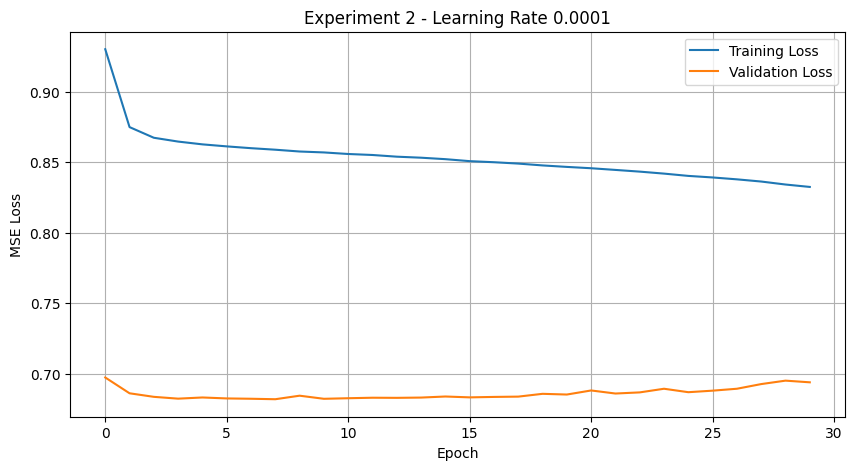

In [43]:
# EXPERIMENT 2 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp2_train_losses,
    label="Training Loss"
)

plt.plot(
    exp2_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 2 - Learning Rate 0.0001")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [44]:
# EXPERIMENT 3 - LEARNING RATE 0.0005

# Create a fresh DNN model
exp3_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.0005
exp3_optimizer = optim.Adam(
    exp3_model.parameters(),
    lr=0.0005
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp3_train_losses = []
exp3_val_losses = []

print("Experiment 3 setup completed!")

Experiment 3 setup completed!


In [45]:
# EXPERIMENT 3 - TRAIN MODEL

for epoch in range(30):

    exp3_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp3_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp3_optimizer.zero_grad()

        loss.backward()

        exp3_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp3_model.eval()

    with torch.no_grad():

        val_predictions = exp3_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp3_train_losses.append(train_loss)
    exp3_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 3 completed!")

Epoch [1/30], Train Loss: 0.8864, Val Loss: 0.6859
Epoch [2/30], Train Loss: 0.8667, Val Loss: 0.6836
Epoch [3/30], Train Loss: 0.8632, Val Loss: 0.6842
Epoch [4/30], Train Loss: 0.8603, Val Loss: 0.6836
Epoch [5/30], Train Loss: 0.8570, Val Loss: 0.6870
Epoch [6/30], Train Loss: 0.8539, Val Loss: 0.6839
Epoch [7/30], Train Loss: 0.8512, Val Loss: 0.6905
Epoch [8/30], Train Loss: 0.8468, Val Loss: 0.6886
Epoch [9/30], Train Loss: 0.8432, Val Loss: 0.6983
Epoch [10/30], Train Loss: 0.8384, Val Loss: 0.6889
Epoch [11/30], Train Loss: 0.8313, Val Loss: 0.6927
Epoch [12/30], Train Loss: 0.8251, Val Loss: 0.7044
Epoch [13/30], Train Loss: 0.8163, Val Loss: 0.6921
Epoch [14/30], Train Loss: 0.8070, Val Loss: 0.6953
Epoch [15/30], Train Loss: 0.7937, Val Loss: 0.7043
Epoch [16/30], Train Loss: 0.7805, Val Loss: 0.7080
Epoch [17/30], Train Loss: 0.7626, Val Loss: 0.7166
Epoch [18/30], Train Loss: 0.7474, Val Loss: 0.7662
Epoch [19/30], Train Loss: 0.7335, Val Loss: 0.7099
Epoch [20/30], Train 

In [46]:
# EXPERIMENT 3 - EVALUATE MODEL

exp3_model.eval()

with torch.no_grad():

    exp3_val_scaled = exp3_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp3_val_predictions = target_scaler.inverse_transform(
        exp3_val_scaled
    )

# Calculate validation MSE
exp3_val_mse = mean_squared_error(
    y_val,
    exp3_val_predictions
)

print("Experiment 3 Validation MSE:", exp3_val_mse)

Experiment 3 Validation MSE: 5426939392.0


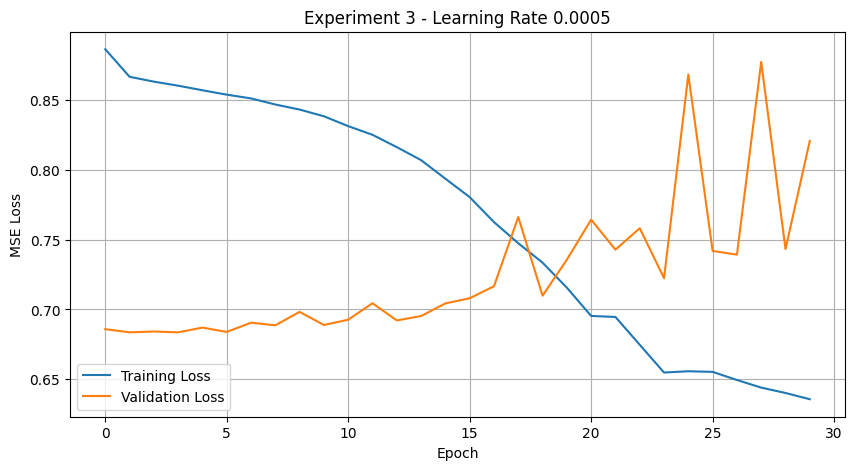

In [47]:
# EXPERIMENT 3 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp3_train_losses,
    label="Training Loss"
)

plt.plot(
    exp3_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 3 - Learning Rate 0.0005")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [48]:
# EXPERIMENT 4 - LEARNING RATE 0.001

# Create a fresh DNN model
exp4_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.001
exp4_optimizer = optim.Adam(
    exp4_model.parameters(),
    lr=0.001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp4_train_losses = []
exp4_val_losses = []

print("Experiment 4 setup completed!")

Experiment 4 setup completed!


In [49]:
# EXPERIMENT 4 - TRAIN MODEL

for epoch in range(30):

    exp4_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp4_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp4_optimizer.zero_grad()

        loss.backward()

        exp4_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp4_model.eval()

    with torch.no_grad():

        val_predictions = exp4_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp4_train_losses.append(train_loss)
    exp4_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 4 completed!")

Epoch [1/30], Train Loss: 0.8815, Val Loss: 0.6856
Epoch [2/30], Train Loss: 0.8659, Val Loss: 0.6879
Epoch [3/30], Train Loss: 0.8618, Val Loss: 0.6816
Epoch [4/30], Train Loss: 0.8569, Val Loss: 0.6820
Epoch [5/30], Train Loss: 0.8537, Val Loss: 0.6827
Epoch [6/30], Train Loss: 0.8470, Val Loss: 0.6840
Epoch [7/30], Train Loss: 0.8401, Val Loss: 0.6943
Epoch [8/30], Train Loss: 0.8349, Val Loss: 0.7013
Epoch [9/30], Train Loss: 0.8260, Val Loss: 0.6983
Epoch [10/30], Train Loss: 0.8123, Val Loss: 0.6960
Epoch [11/30], Train Loss: 0.8000, Val Loss: 0.7029
Epoch [12/30], Train Loss: 0.7804, Val Loss: 0.7218
Epoch [13/30], Train Loss: 0.7649, Val Loss: 0.7435
Epoch [14/30], Train Loss: 0.7461, Val Loss: 0.7095
Epoch [15/30], Train Loss: 0.7221, Val Loss: 0.7077
Epoch [16/30], Train Loss: 0.7070, Val Loss: 0.7186
Epoch [17/30], Train Loss: 0.6864, Val Loss: 0.7008
Epoch [18/30], Train Loss: 0.6710, Val Loss: 0.7338
Epoch [19/30], Train Loss: 0.6543, Val Loss: 0.8185
Epoch [20/30], Train 

In [50]:
# EXPERIMENT 4 - EVALUATE MODEL

exp4_model.eval()

with torch.no_grad():

    exp4_val_scaled = exp4_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp4_val_predictions = target_scaler.inverse_transform(
        exp4_val_scaled
    )

# Calculate validation MSE
exp4_val_mse = mean_squared_error(
    y_val,
    exp4_val_predictions
)

print("Experiment 4 Validation MSE:", exp4_val_mse)

Experiment 4 Validation MSE: 4866651136.0


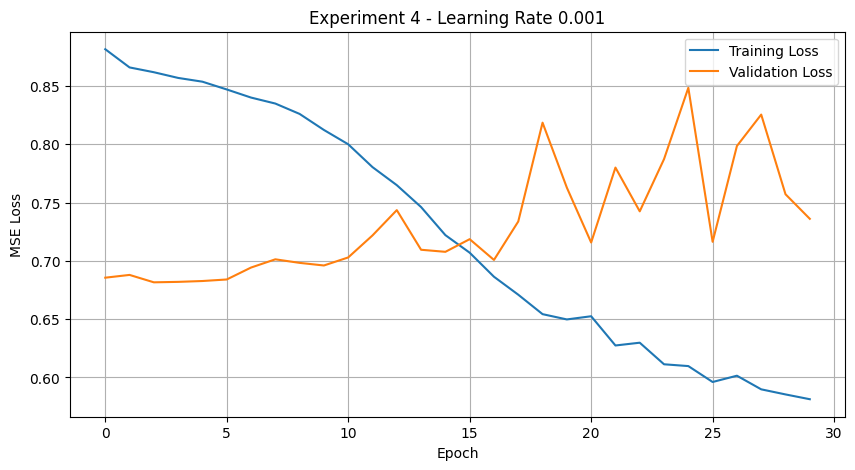

In [51]:
# EXPERIMENT 4 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp4_train_losses,
    label="Training Loss"
)

plt.plot(
    exp4_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 4 - Learning Rate 0.001")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [52]:
# EXPERIMENT 5 - LEARNING RATE 0.01

# Create a fresh DNN model
exp5_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.01
exp5_optimizer = optim.Adam(
    exp5_model.parameters(),
    lr=0.01
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp5_train_losses = []
exp5_val_losses = []

print("Experiment 5 setup completed!")

Experiment 5 setup completed!


In [53]:
# EXPERIMENT 5 - TRAIN MODEL

for epoch in range(30):

    exp5_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp5_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp5_optimizer.zero_grad()

        loss.backward()

        exp5_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp5_model.eval()

    with torch.no_grad():

        val_predictions = exp5_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp5_train_losses.append(train_loss)
    exp5_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 5 completed!")

Epoch [1/30], Train Loss: 0.8849, Val Loss: 0.6915
Epoch [2/30], Train Loss: 0.8705, Val Loss: 0.6982
Epoch [3/30], Train Loss: 0.8689, Val Loss: 0.6888
Epoch [4/30], Train Loss: 0.8645, Val Loss: 0.6894
Epoch [5/30], Train Loss: 0.8603, Val Loss: 0.6889
Epoch [6/30], Train Loss: 0.8578, Val Loss: 0.6896
Epoch [7/30], Train Loss: 0.8549, Val Loss: 0.6973
Epoch [8/30], Train Loss: 0.8521, Val Loss: 0.7059
Epoch [9/30], Train Loss: 0.8461, Val Loss: 0.7026
Epoch [10/30], Train Loss: 0.8435, Val Loss: 0.7253
Epoch [11/30], Train Loss: 0.8286, Val Loss: 0.6947
Epoch [12/30], Train Loss: 0.8276, Val Loss: 0.6985
Epoch [13/30], Train Loss: 0.8223, Val Loss: 0.7115
Epoch [14/30], Train Loss: 0.8112, Val Loss: 0.7056
Epoch [15/30], Train Loss: 0.8018, Val Loss: 0.7361
Epoch [16/30], Train Loss: 0.7955, Val Loss: 0.7005
Epoch [17/30], Train Loss: 0.7811, Val Loss: 0.7109
Epoch [18/30], Train Loss: 0.7748, Val Loss: 0.7007
Epoch [19/30], Train Loss: 0.7691, Val Loss: 0.7112
Epoch [20/30], Train 

In [54]:
# EXPERIMENT 5 - EVALUATE MODEL

exp5_model.eval()

with torch.no_grad():

    exp5_val_scaled = exp5_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp5_val_predictions = target_scaler.inverse_transform(
        exp5_val_scaled
    )

# Calculate validation MSE
exp5_val_mse = mean_squared_error(
    y_val,
    exp5_val_predictions
)

print("Experiment 5 Validation MSE:", exp5_val_mse)

Experiment 5 Validation MSE: 4919202816.0


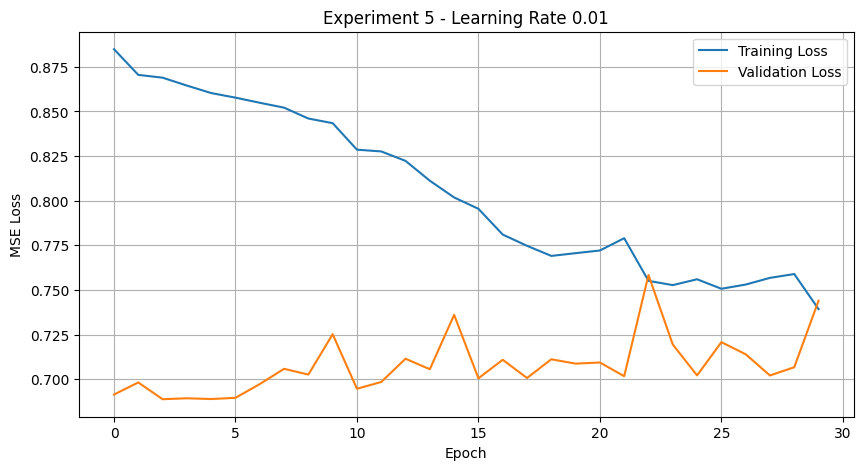

In [55]:
# EXPERIMENT 5 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp5_train_losses,
    label="Training Loss"
)

plt.plot(
    exp5_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 5 - Learning Rate 0.01")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [56]:
# EXPERIMENT 6 - LEARNING RATE 0.1

# Create a fresh DNN model
exp6_model = DeepNeuralNetwork(input_size=315)

# Define optimizer with learning rate 0.1
exp6_optimizer = optim.Adam(
    exp6_model.parameters(),
    lr=0.1
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp6_train_losses = []
exp6_val_losses = []

print("Experiment 6 setup completed!")

Experiment 6 setup completed!


In [57]:
# EXPERIMENT 6 - TRAIN MODEL

for epoch in range(30):

    exp6_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp6_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp6_optimizer.zero_grad()

        loss.backward()

        exp6_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp6_model.eval()

    with torch.no_grad():

        val_predictions = exp6_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp6_train_losses.append(train_loss)
    exp6_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 6 completed!")

Epoch [1/30], Train Loss: 1.1886, Val Loss: 0.7238
Epoch [2/30], Train Loss: 0.8899, Val Loss: 0.6990
Epoch [3/30], Train Loss: 0.8899, Val Loss: 0.7104
Epoch [4/30], Train Loss: 0.8916, Val Loss: 0.7107
Epoch [5/30], Train Loss: 0.8951, Val Loss: 0.6999
Epoch [6/30], Train Loss: 0.8905, Val Loss: 0.7347
Epoch [7/30], Train Loss: 0.8896, Val Loss: 0.6937
Epoch [8/30], Train Loss: 0.8861, Val Loss: 0.6983
Epoch [9/30], Train Loss: 0.8909, Val Loss: 0.7523
Epoch [10/30], Train Loss: 0.8857, Val Loss: 0.7406
Epoch [11/30], Train Loss: 0.8847, Val Loss: 0.6926
Epoch [12/30], Train Loss: 0.8853, Val Loss: 0.6929
Epoch [13/30], Train Loss: 0.8891, Val Loss: 0.6994
Epoch [14/30], Train Loss: 0.8841, Val Loss: 0.7260
Epoch [15/30], Train Loss: 0.8873, Val Loss: 0.6979
Epoch [16/30], Train Loss: 0.8858, Val Loss: 0.6959
Epoch [17/30], Train Loss: 0.8900, Val Loss: 0.6970
Epoch [18/30], Train Loss: 0.8854, Val Loss: 0.6907
Epoch [19/30], Train Loss: 0.8852, Val Loss: 0.6949
Epoch [20/30], Train 

In [58]:
# EXPERIMENT 6 - EVALUATE MODEL

exp6_model.eval()

with torch.no_grad():

    exp6_val_scaled = exp6_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp6_val_predictions = target_scaler.inverse_transform(
        exp6_val_scaled
    )

# Calculate validation MSE
exp6_val_mse = mean_squared_error(
    y_val,
    exp6_val_predictions
)

print("Experiment 6 Validation MSE:", exp6_val_mse)

Experiment 6 Validation MSE: 4603274752.0


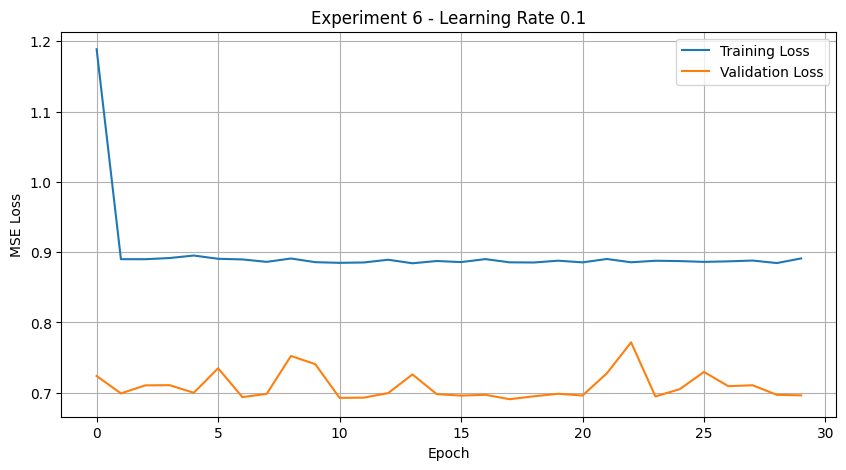

In [59]:
# EXPERIMENT 6 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp6_train_losses,
    label="Training Loss"
)

plt.plot(
    exp6_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 6 - Learning Rate 0.1")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [60]:
# EXPERIMENT 7 - ADAM OPTIMIZER

# Create a fresh DNN model
exp7_model = DeepNeuralNetwork(input_size=315)

# Define Adam optimizer
exp7_optimizer = optim.Adam(
    exp7_model.parameters(),
    lr=0.00001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp7_train_losses = []
exp7_val_losses = []

print("Experiment 7 setup completed!")

Experiment 7 setup completed!


In [61]:
# EXPERIMENT 7 - TRAIN MODEL

for epoch in range(30):

    exp7_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp7_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp7_optimizer.zero_grad()

        loss.backward()

        exp7_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp7_model.eval()

    with torch.no_grad():

        val_predictions = exp7_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp7_train_losses.append(train_loss)
    exp7_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 7 completed!")

Epoch [1/30], Train Loss: 1.0058, Val Loss: 0.8119
Epoch [2/30], Train Loss: 0.9832, Val Loss: 0.7838
Epoch [3/30], Train Loss: 0.9496, Val Loss: 0.7474
Epoch [4/30], Train Loss: 0.9205, Val Loss: 0.7262
Epoch [5/30], Train Loss: 0.9066, Val Loss: 0.7172
Epoch [6/30], Train Loss: 0.8996, Val Loss: 0.7120
Epoch [7/30], Train Loss: 0.8947, Val Loss: 0.7080
Epoch [8/30], Train Loss: 0.8908, Val Loss: 0.7049
Epoch [9/30], Train Loss: 0.8876, Val Loss: 0.7023
Epoch [10/30], Train Loss: 0.8849, Val Loss: 0.7000
Epoch [11/30], Train Loss: 0.8826, Val Loss: 0.6982
Epoch [12/30], Train Loss: 0.8806, Val Loss: 0.6965
Epoch [13/30], Train Loss: 0.8788, Val Loss: 0.6950
Epoch [14/30], Train Loss: 0.8773, Val Loss: 0.6938
Epoch [15/30], Train Loss: 0.8758, Val Loss: 0.6926
Epoch [16/30], Train Loss: 0.8746, Val Loss: 0.6916
Epoch [17/30], Train Loss: 0.8735, Val Loss: 0.6907
Epoch [18/30], Train Loss: 0.8725, Val Loss: 0.6900
Epoch [19/30], Train Loss: 0.8716, Val Loss: 0.6892
Epoch [20/30], Train 

In [62]:
# EXPERIMENT 7 - EVALUATE MODEL

exp7_model.eval()

with torch.no_grad():

    exp7_val_scaled = exp7_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp7_val_predictions = target_scaler.inverse_transform(
        exp7_val_scaled
    )

# Calculate validation MSE
exp7_val_mse = mean_squared_error(
    y_val,
    exp7_val_predictions
)

print("Experiment 7 Validation MSE:", exp7_val_mse)

Experiment 7 Validation MSE: 4524561408.0


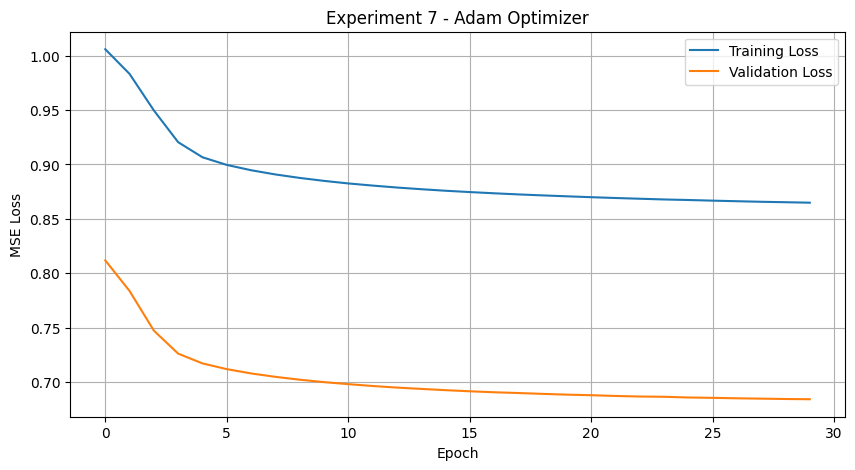

In [63]:
# EXPERIMENT 7 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp7_train_losses,
    label="Training Loss"
)

plt.plot(
    exp7_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 7 - Adam Optimizer")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [64]:
# EXPERIMENT 8 - SGD OPTIMIZER

# Create a fresh DNN model
exp8_model = DeepNeuralNetwork(input_size=315)

# Define SGD optimizer
exp8_optimizer = optim.SGD(
    exp8_model.parameters(),
    lr=0.00001
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp8_train_losses = []
exp8_val_losses = []

print("Experiment 8 setup completed!")

Experiment 8 setup completed!


In [65]:
# EXPERIMENT 8 - TRAIN MODEL

for epoch in range(30):

    exp8_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp8_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp8_optimizer.zero_grad()

        loss.backward()

        exp8_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp8_model.eval()

    with torch.no_grad():

        val_predictions = exp8_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp8_train_losses.append(train_loss)
    exp8_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 8 completed!")

Epoch [1/30], Train Loss: 1.0027, Val Loss: 0.8192
Epoch [2/30], Train Loss: 1.0027, Val Loss: 0.8191
Epoch [3/30], Train Loss: 1.0026, Val Loss: 0.8191
Epoch [4/30], Train Loss: 1.0026, Val Loss: 0.8190
Epoch [5/30], Train Loss: 1.0025, Val Loss: 0.8190
Epoch [6/30], Train Loss: 1.0024, Val Loss: 0.8189
Epoch [7/30], Train Loss: 1.0024, Val Loss: 0.8188
Epoch [8/30], Train Loss: 1.0023, Val Loss: 0.8188
Epoch [9/30], Train Loss: 1.0023, Val Loss: 0.8187
Epoch [10/30], Train Loss: 1.0022, Val Loss: 0.8187
Epoch [11/30], Train Loss: 1.0022, Val Loss: 0.8186
Epoch [12/30], Train Loss: 1.0021, Val Loss: 0.8186
Epoch [13/30], Train Loss: 1.0021, Val Loss: 0.8185
Epoch [14/30], Train Loss: 1.0020, Val Loss: 0.8185
Epoch [15/30], Train Loss: 1.0020, Val Loss: 0.8184
Epoch [16/30], Train Loss: 1.0019, Val Loss: 0.8184
Epoch [17/30], Train Loss: 1.0019, Val Loss: 0.8183
Epoch [18/30], Train Loss: 1.0018, Val Loss: 0.8183
Epoch [19/30], Train Loss: 1.0018, Val Loss: 0.8182
Epoch [20/30], Train 

In [66]:
# EXPERIMENT 8 - EVALUATE MODEL

exp8_model.eval()

with torch.no_grad():

    exp8_val_scaled = exp8_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp8_val_predictions = target_scaler.inverse_transform(
        exp8_val_scaled
    )

# Calculate validation MSE
exp8_val_mse = mean_squared_error(
    y_val,
    exp8_val_predictions
)

print("Experiment 8 Validation MSE:", exp8_val_mse)

Experiment 8 Validation MSE: 5406868480.0


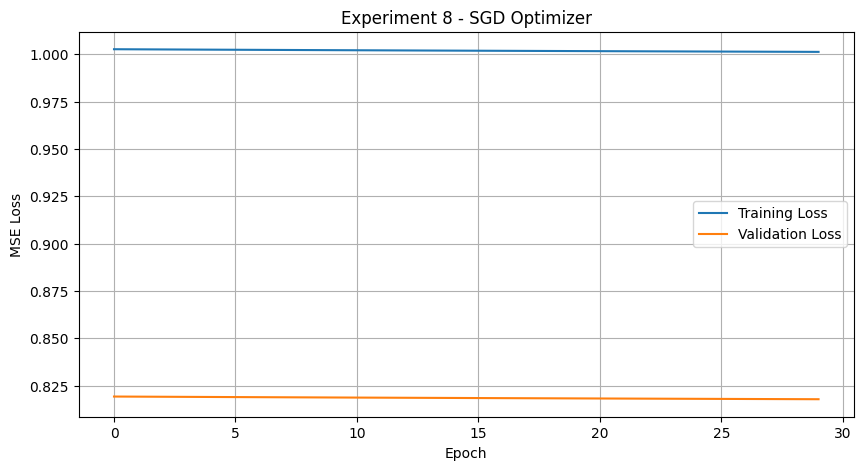

In [67]:
# EXPERIMENT 8 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp8_train_losses,
    label="Training Loss"
)

plt.plot(
    exp8_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 8 - SGD Optimizer")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [68]:
# EXPERIMENT 9 - SGD WITH MOMENTUM

# Create a fresh DNN model
exp9_model = DeepNeuralNetwork(input_size=315)

# Define SGD optimizer with Momentum
exp9_optimizer = optim.SGD(
    exp9_model.parameters(),
    lr=0.00001,
    momentum=0.9
)

# Define loss function
criterion = nn.MSELoss()

# Store losses
exp9_train_losses = []
exp9_val_losses = []

print("Experiment 9 setup completed!")

Experiment 9 setup completed!


In [69]:
# EXPERIMENT 9 - TRAIN MODEL

for epoch in range(30):

    exp9_model.train()

    total_train_loss = 0

    for X_batch, y_batch in dnn_train_loader:

        # Forward pass
        predictions = exp9_model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        exp9_optimizer.zero_grad()

        loss.backward()

        exp9_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp9_model.eval()

    with torch.no_grad():

        val_predictions = exp9_model(X_val_tensor)

        val_loss = criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp9_train_losses.append(train_loss)
    exp9_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 9 completed!")

Epoch [1/30], Train Loss: 1.0130, Val Loss: 0.8270
Epoch [2/30], Train Loss: 1.0084, Val Loss: 0.8231
Epoch [3/30], Train Loss: 1.0051, Val Loss: 0.8202
Epoch [4/30], Train Loss: 1.0027, Val Loss: 0.8181
Epoch [5/30], Train Loss: 1.0008, Val Loss: 0.8165
Epoch [6/30], Train Loss: 0.9995, Val Loss: 0.8153
Epoch [7/30], Train Loss: 0.9984, Val Loss: 0.8144
Epoch [8/30], Train Loss: 0.9976, Val Loss: 0.8136
Epoch [9/30], Train Loss: 0.9969, Val Loss: 0.8130
Epoch [10/30], Train Loss: 0.9963, Val Loss: 0.8125
Epoch [11/30], Train Loss: 0.9958, Val Loss: 0.8120
Epoch [12/30], Train Loss: 0.9954, Val Loss: 0.8116
Epoch [13/30], Train Loss: 0.9950, Val Loss: 0.8112
Epoch [14/30], Train Loss: 0.9946, Val Loss: 0.8108
Epoch [15/30], Train Loss: 0.9943, Val Loss: 0.8105
Epoch [16/30], Train Loss: 0.9939, Val Loss: 0.8101
Epoch [17/30], Train Loss: 0.9936, Val Loss: 0.8098
Epoch [18/30], Train Loss: 0.9932, Val Loss: 0.8094
Epoch [19/30], Train Loss: 0.9929, Val Loss: 0.8091
Epoch [20/30], Train 

In [70]:
# EXPERIMENT 9 - EVALUATE MODEL

exp9_model.eval()

with torch.no_grad():

    exp9_val_scaled = exp9_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp9_val_predictions = target_scaler.inverse_transform(
        exp9_val_scaled
    )

# Calculate validation MSE
exp9_val_mse = mean_squared_error(
    y_val,
    exp9_val_predictions
)

print("Experiment 9 Validation MSE:", exp9_val_mse)

Experiment 9 Validation MSE: 5322162176.0


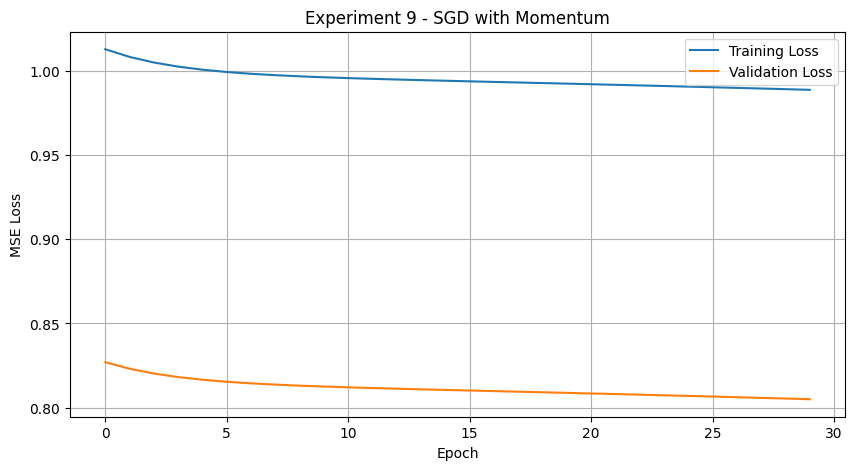

In [71]:
# EXPERIMENT 9 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp9_train_losses,
    label="Training Loss"
)

plt.plot(
    exp9_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 9 - SGD with Momentum")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [72]:
# EXPERIMENT 10 - SETUP BATCH SIZE 16

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp10_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 16
exp10_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# Define loss function
exp10_criterion = nn.MSELoss()

# Define Adam optimizer
exp10_optimizer = optim.Adam(
    exp10_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp10_train_losses = []
exp10_val_losses = []

# Number of epochs
exp10_epochs = 30

print("Experiment 10 setup completed!")

Experiment 10 setup completed!


In [73]:
# EXPERIMENT 10 - TRAIN MODEL (BATCH SIZE 16)

for epoch in range(exp10_epochs):

    # Set model to training mode
    exp10_model.train()

    total_train_loss = 0

    # Loop through training batches
    for X_batch, y_batch in exp10_train_loader:

        # Forward pass
        predictions = exp10_model(X_batch)

        # Calculate loss
        loss = exp10_criterion(predictions, y_batch)

        # Backpropagation
        exp10_optimizer.zero_grad()
        loss.backward()
        exp10_optimizer.step()

        # Accumulate training loss
        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp10_model.eval()

    with torch.no_grad():

        val_predictions = exp10_model(X_val_tensor)

        val_loss = exp10_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp10_train_losses.append(train_loss)
    exp10_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp10_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 10 completed!")

Epoch [1/30], Train Loss: 0.9384, Val Loss: 0.7152
Epoch [2/30], Train Loss: 0.8925, Val Loss: 0.7015
Epoch [3/30], Train Loss: 0.8818, Val Loss: 0.6945
Epoch [4/30], Train Loss: 0.8756, Val Loss: 0.6898
Epoch [5/30], Train Loss: 0.8716, Val Loss: 0.6870
Epoch [6/30], Train Loss: 0.8689, Val Loss: 0.6852
Epoch [7/30], Train Loss: 0.8669, Val Loss: 0.6842
Epoch [8/30], Train Loss: 0.8655, Val Loss: 0.6833
Epoch [9/30], Train Loss: 0.8646, Val Loss: 0.6828
Epoch [10/30], Train Loss: 0.8638, Val Loss: 0.6825
Epoch [11/30], Train Loss: 0.8632, Val Loss: 0.6822
Epoch [12/30], Train Loss: 0.8625, Val Loss: 0.6820
Epoch [13/30], Train Loss: 0.8620, Val Loss: 0.6819
Epoch [14/30], Train Loss: 0.8616, Val Loss: 0.6818
Epoch [15/30], Train Loss: 0.8611, Val Loss: 0.6818
Epoch [16/30], Train Loss: 0.8608, Val Loss: 0.6816
Epoch [17/30], Train Loss: 0.8603, Val Loss: 0.6815
Epoch [18/30], Train Loss: 0.8599, Val Loss: 0.6816
Epoch [19/30], Train Loss: 0.8594, Val Loss: 0.6816
Epoch [20/30], Train 

In [74]:
# EXPERIMENT 10 - EVALUATE MODEL

exp10_model.eval()

with torch.no_grad():

    exp10_val_scaled = exp10_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp10_val_predictions = target_scaler.inverse_transform(
        exp10_val_scaled
    )

    # Calculate validation MSE
    exp10_val_mse = mean_squared_error(
        y_val,
        exp10_val_predictions
    )

print("Experiment 10 Validation MSE:", exp10_val_mse)


Experiment 10 Validation MSE: 4508868608.0


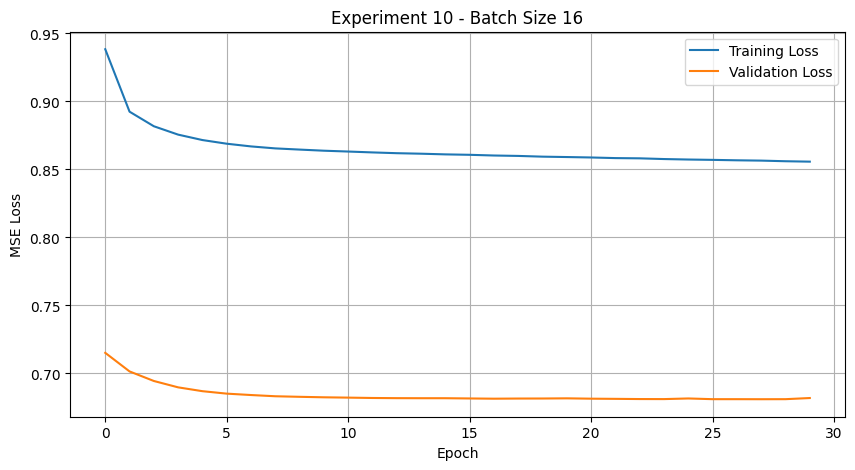

In [75]:
# EXPERIMENT 10 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp10_train_losses,
    label="Training Loss"
)

plt.plot(
    exp10_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 10 - Batch Size 16")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()


In [76]:
# EXPERIMENT 11 - SETUP BATCH SIZE 32

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp11_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 32
exp11_train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

# Define loss function
exp11_criterion = nn.MSELoss()

# Define Adam optimizer
exp11_optimizer = optim.Adam(
    exp11_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp11_train_losses = []
exp11_val_losses = []

# Number of epochs
exp11_epochs = 30

print("Experiment 11 setup completed!")

Experiment 11 setup completed!


In [77]:
# EXPERIMENT 11 - TRAIN MODEL

for epoch in range(exp11_epochs):

    exp11_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp11_train_loader:

        # Forward pass
        predictions = exp11_model(X_batch)

        # Calculate loss
        loss = exp11_criterion(predictions, y_batch)

        # Backpropagation
        exp11_optimizer.zero_grad()
        loss.backward()
        exp11_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp11_model.eval()

    with torch.no_grad():

        val_predictions = exp11_model(X_val_tensor)

        val_loss = exp11_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp11_train_losses.append(train_loss)
    exp11_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp11_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 11 completed!")

Epoch [1/30], Train Loss: 0.9559, Val Loss: 0.7242
Epoch [2/30], Train Loss: 0.9005, Val Loss: 0.7087
Epoch [3/30], Train Loss: 0.8890, Val Loss: 0.7008
Epoch [4/30], Train Loss: 0.8820, Val Loss: 0.6955
Epoch [5/30], Train Loss: 0.8772, Val Loss: 0.6920
Epoch [6/30], Train Loss: 0.8739, Val Loss: 0.6895
Epoch [7/30], Train Loss: 0.8712, Val Loss: 0.6877
Epoch [8/30], Train Loss: 0.8691, Val Loss: 0.6862
Epoch [9/30], Train Loss: 0.8677, Val Loss: 0.6853
Epoch [10/30], Train Loss: 0.8665, Val Loss: 0.6844
Epoch [11/30], Train Loss: 0.8655, Val Loss: 0.6840
Epoch [12/30], Train Loss: 0.8646, Val Loss: 0.6834
Epoch [13/30], Train Loss: 0.8639, Val Loss: 0.6831
Epoch [14/30], Train Loss: 0.8633, Val Loss: 0.6828
Epoch [15/30], Train Loss: 0.8628, Val Loss: 0.6827
Epoch [16/30], Train Loss: 0.8623, Val Loss: 0.6825
Epoch [17/30], Train Loss: 0.8618, Val Loss: 0.6823
Epoch [18/30], Train Loss: 0.8614, Val Loss: 0.6823
Epoch [19/30], Train Loss: 0.8609, Val Loss: 0.6823
Epoch [20/30], Train 

In [78]:
# EXPERIMENT 11 - EVALUATE MODEL

exp11_model.eval()

with torch.no_grad():

    exp11_val_scaled = exp11_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp11_val_predictions = target_scaler.inverse_transform(
        exp11_val_scaled
    )

    # Calculate validation MSE
    exp11_val_mse = mean_squared_error(
        y_val,
        exp11_val_predictions
    )

print("Experiment 11 Validation MSE:", exp11_val_mse)

Experiment 11 Validation MSE: 4511033856.0


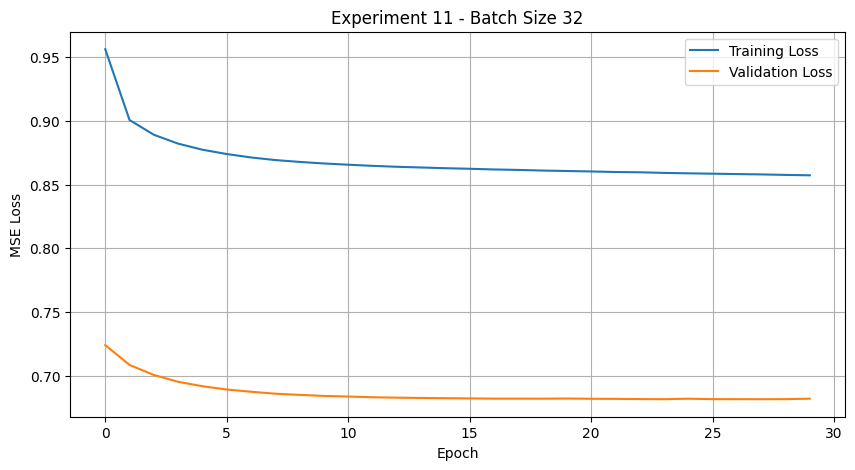

In [79]:
# EXPERIMENT 11 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp11_train_losses,
    label="Training Loss"
)

plt.plot(
    exp11_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 11 - Batch Size 32")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [80]:
# EXPERIMENT 12 - SETUP BATCH SIZE 64

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp12_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 64
exp12_train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# Define loss function
exp12_criterion = nn.MSELoss()

# Define Adam optimizer
exp12_optimizer = optim.Adam(
    exp12_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp12_train_losses = []
exp12_val_losses = []

# Number of epochs
exp12_epochs = 30

print("Experiment 12 setup completed!")

Experiment 12 setup completed!


In [81]:
# EXPERIMENT 12 - TRAIN MODEL

for epoch in range(exp12_epochs):

    exp12_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp12_train_loader:

        # Forward pass
        predictions = exp12_model(X_batch)

        # Calculate loss
        loss = exp12_criterion(predictions, y_batch)

        # Backpropagation
        exp12_optimizer.zero_grad()
        loss.backward()
        exp12_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp12_model.eval()

    with torch.no_grad():

        val_predictions = exp12_model(X_val_tensor)

        val_loss = exp12_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp12_train_losses.append(train_loss)
    exp12_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp12_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 12 completed!")

Epoch [1/30], Train Loss: 0.9782, Val Loss: 0.7505
Epoch [2/30], Train Loss: 0.9130, Val Loss: 0.7169
Epoch [3/30], Train Loss: 0.8970, Val Loss: 0.7080
Epoch [4/30], Train Loss: 0.8893, Val Loss: 0.7021
Epoch [5/30], Train Loss: 0.8839, Val Loss: 0.6980
Epoch [6/30], Train Loss: 0.8799, Val Loss: 0.6948
Epoch [7/30], Train Loss: 0.8768, Val Loss: 0.6925
Epoch [8/30], Train Loss: 0.8743, Val Loss: 0.6905
Epoch [9/30], Train Loss: 0.8723, Val Loss: 0.6891
Epoch [10/30], Train Loss: 0.8706, Val Loss: 0.6879
Epoch [11/30], Train Loss: 0.8693, Val Loss: 0.6870
Epoch [12/30], Train Loss: 0.8681, Val Loss: 0.6861
Epoch [13/30], Train Loss: 0.8671, Val Loss: 0.6855
Epoch [14/30], Train Loss: 0.8663, Val Loss: 0.6849
Epoch [15/30], Train Loss: 0.8656, Val Loss: 0.6846
Epoch [16/30], Train Loss: 0.8649, Val Loss: 0.6842
Epoch [17/30], Train Loss: 0.8643, Val Loss: 0.6838
Epoch [18/30], Train Loss: 0.8638, Val Loss: 0.6836
Epoch [19/30], Train Loss: 0.8633, Val Loss: 0.6834
Epoch [20/30], Train 

In [82]:
# EXPERIMENT 12 - EVALUATE MODEL

exp12_model.eval()

with torch.no_grad():

    exp12_val_scaled = exp12_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp12_val_predictions = target_scaler.inverse_transform(
        exp12_val_scaled
    )

    # Calculate validation MSE
    exp12_val_mse = mean_squared_error(
        y_val,
        exp12_val_predictions
    )

print("Experiment 12 Validation MSE:", exp12_val_mse)

Experiment 12 Validation MSE: 4514146816.0


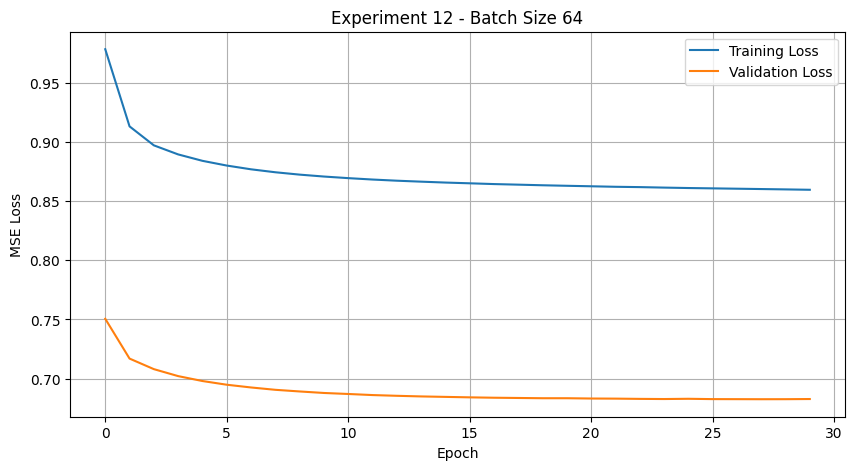

In [83]:
# EXPERIMENT 12 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp12_train_losses,
    label="Training Loss"
)

plt.plot(
    exp12_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 12 - Batch Size 64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [84]:
# EXPERIMENT 13 - SETUP BATCH SIZE 128

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp13_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 128
exp13_train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

# Define loss function
exp13_criterion = nn.MSELoss()

# Define Adam optimizer
exp13_optimizer = optim.Adam(
    exp13_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp13_train_losses = []
exp13_val_losses = []

# Number of epochs
exp13_epochs = 30

print("Experiment 13 setup completed!")

Experiment 13 setup completed!


In [85]:
# EXPERIMENT 13 - TRAIN MODEL

for epoch in range(exp13_epochs):

    exp13_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp13_train_loader:

        # Forward pass
        predictions = exp13_model(X_batch)

        # Calculate loss
        loss = exp13_criterion(predictions, y_batch)

        # Backpropagation
        exp13_optimizer.zero_grad()
        loss.backward()
        exp13_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp13_model.eval()

    with torch.no_grad():

        val_predictions = exp13_model(X_val_tensor)

        val_loss = exp13_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp13_train_losses.append(train_loss)
    exp13_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp13_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 13 completed!")

Epoch [1/30], Train Loss: 0.9929, Val Loss: 0.7926
Epoch [2/30], Train Loss: 0.9458, Val Loss: 0.7333
Epoch [3/30], Train Loss: 0.9083, Val Loss: 0.7167
Epoch [4/30], Train Loss: 0.8980, Val Loss: 0.7097
Epoch [5/30], Train Loss: 0.8918, Val Loss: 0.7049
Epoch [6/30], Train Loss: 0.8872, Val Loss: 0.7012
Epoch [7/30], Train Loss: 0.8835, Val Loss: 0.6983
Epoch [8/30], Train Loss: 0.8806, Val Loss: 0.6959
Epoch [9/30], Train Loss: 0.8781, Val Loss: 0.6941
Epoch [10/30], Train Loss: 0.8761, Val Loss: 0.6924
Epoch [11/30], Train Loss: 0.8744, Val Loss: 0.6911
Epoch [12/30], Train Loss: 0.8728, Val Loss: 0.6899
Epoch [13/30], Train Loss: 0.8715, Val Loss: 0.6890
Epoch [14/30], Train Loss: 0.8704, Val Loss: 0.6881
Epoch [15/30], Train Loss: 0.8694, Val Loss: 0.6874
Epoch [16/30], Train Loss: 0.8685, Val Loss: 0.6868
Epoch [17/30], Train Loss: 0.8677, Val Loss: 0.6863
Epoch [18/30], Train Loss: 0.8670, Val Loss: 0.6858
Epoch [19/30], Train Loss: 0.8664, Val Loss: 0.6854
Epoch [20/30], Train 

In [86]:
# EXPERIMENT 13 - EVALUATE MODEL

exp13_model.eval()

with torch.no_grad():

    exp13_val_scaled = exp13_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp13_val_predictions = target_scaler.inverse_transform(
        exp13_val_scaled
    )

    # Calculate validation MSE
    exp13_val_mse = mean_squared_error(
        y_val,
        exp13_val_predictions
    )

print("Experiment 13 Validation MSE:", exp13_val_mse)

Experiment 13 Validation MSE: 4518858240.0


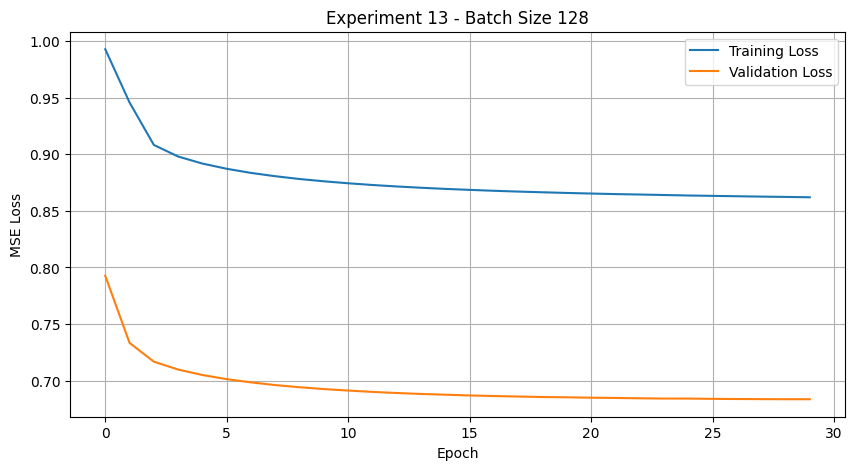

In [87]:
# EXPERIMENT 13 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp13_train_losses,
    label="Training Loss"
)

plt.plot(
    exp13_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 13 - Batch Size 128")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [88]:
# EXPERIMENT 14 - SETUP BATCH SIZE 256

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp14_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 256
exp14_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# Define loss function
exp14_criterion = nn.MSELoss()

# Define Adam optimizer
exp14_optimizer = optim.Adam(
    exp14_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp14_train_losses = []
exp14_val_losses = []

# Number of epochs
exp14_epochs = 30

print("Experiment 14 setup completed!")

Experiment 14 setup completed!


In [89]:
# EXPERIMENT 14 - TRAIN MODEL

for epoch in range(exp14_epochs):

    exp14_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp14_train_loader:

        # Forward pass
        predictions = exp14_model(X_batch)

        # Calculate loss
        loss = exp14_criterion(predictions, y_batch)

        # Backpropagation
        exp14_optimizer.zero_grad()
        loss.backward()
        exp14_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp14_model.eval()

    with torch.no_grad():

        val_predictions = exp14_model(X_val_tensor)

        val_loss = exp14_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp14_train_losses.append(train_loss)
    exp14_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp14_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 14 completed!")

Epoch [1/30], Train Loss: 0.9980, Val Loss: 0.8093
Epoch [2/30], Train Loss: 0.9822, Val Loss: 0.7832
Epoch [3/30], Train Loss: 0.9472, Val Loss: 0.7427
Epoch [4/30], Train Loss: 0.9157, Val Loss: 0.7224
Epoch [5/30], Train Loss: 0.9036, Val Loss: 0.7150
Epoch [6/30], Train Loss: 0.8975, Val Loss: 0.7102
Epoch [7/30], Train Loss: 0.8929, Val Loss: 0.7065
Epoch [8/30], Train Loss: 0.8892, Val Loss: 0.7034
Epoch [9/30], Train Loss: 0.8861, Val Loss: 0.7009
Epoch [10/30], Train Loss: 0.8836, Val Loss: 0.6989
Epoch [11/30], Train Loss: 0.8814, Val Loss: 0.6971
Epoch [12/30], Train Loss: 0.8795, Val Loss: 0.6956
Epoch [13/30], Train Loss: 0.8778, Val Loss: 0.6942
Epoch [14/30], Train Loss: 0.8763, Val Loss: 0.6930
Epoch [15/30], Train Loss: 0.8750, Val Loss: 0.6921
Epoch [16/30], Train Loss: 0.8739, Val Loss: 0.6911
Epoch [17/30], Train Loss: 0.8728, Val Loss: 0.6903
Epoch [18/30], Train Loss: 0.8719, Val Loss: 0.6896
Epoch [19/30], Train Loss: 0.8710, Val Loss: 0.6889
Epoch [20/30], Train 

In [90]:
# EXPERIMENT 14 - EVALUATE MODEL

exp14_model.eval()

with torch.no_grad():

    exp14_val_scaled = exp14_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp14_val_predictions = target_scaler.inverse_transform(
        exp14_val_scaled
    )

    # Calculate validation MSE
    exp14_val_mse = mean_squared_error(
        y_val,
        exp14_val_predictions
    )

print("Experiment 14 Validation MSE:", exp14_val_mse)

Experiment 14 Validation MSE: 4528403968.0


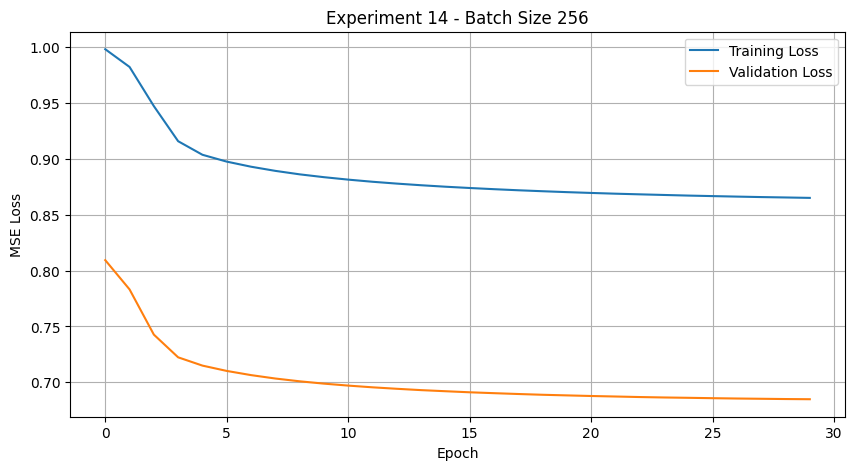

In [91]:
# EXPERIMENT 14 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp14_train_losses,
    label="Training Loss"
)

plt.plot(
    exp14_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 14 - Batch Size 256")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [92]:
# EXPERIMENT 15 - SETUP BATCH SIZE 512

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp15_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 512
exp15_train_loader = DataLoader(
    train_dataset,
    batch_size=512,
    shuffle=True
)

# Define loss function
exp15_criterion = nn.MSELoss()

# Define Adam optimizer
exp15_optimizer = optim.Adam(
    exp15_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp15_train_losses = []
exp15_val_losses = []

# Number of epochs
exp15_epochs = 30

print("Experiment 15 setup completed!")

Experiment 15 setup completed!


In [93]:
# EXPERIMENT 15 - TRAIN MODEL

for epoch in range(exp15_epochs):

    exp15_model.train()

    total_train_loss = 0

    # Training loop
    for X_batch, y_batch in exp15_train_loader:

        # Forward pass
        predictions = exp15_model(X_batch)

        # Calculate loss
        loss = exp15_criterion(predictions, y_batch)

        # Backpropagation
        exp15_optimizer.zero_grad()
        loss.backward()
        exp15_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp15_model.eval()

    with torch.no_grad():

        val_predictions = exp15_model(X_val_tensor)

        val_loss = exp15_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Store losses
    exp15_train_losses.append(train_loss)
    exp15_val_losses.append(val_loss)

    # Print results
    print(
        f"Epoch [{epoch+1}/{exp15_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 15 completed!")

Epoch [1/30], Train Loss: 1.0000, Val Loss: 0.8143
Epoch [2/30], Train Loss: 0.9949, Val Loss: 0.8074
Epoch [3/30], Train Loss: 0.9851, Val Loss: 0.7939
Epoch [4/30], Train Loss: 0.9679, Val Loss: 0.7725
Epoch [5/30], Train Loss: 0.9447, Val Loss: 0.7480
Epoch [6/30], Train Loss: 0.9232, Val Loss: 0.7299
Epoch [7/30], Train Loss: 0.9102, Val Loss: 0.7209
Epoch [8/30], Train Loss: 0.9035, Val Loss: 0.7160
Epoch [9/30], Train Loss: 0.8991, Val Loss: 0.7123
Epoch [10/30], Train Loss: 0.8956, Val Loss: 0.7093
Epoch [11/30], Train Loss: 0.8925, Val Loss: 0.7067
Epoch [12/30], Train Loss: 0.8898, Val Loss: 0.7044
Epoch [13/30], Train Loss: 0.8874, Val Loss: 0.7025
Epoch [14/30], Train Loss: 0.8854, Val Loss: 0.7007
Epoch [15/30], Train Loss: 0.8835, Val Loss: 0.6992
Epoch [16/30], Train Loss: 0.8819, Val Loss: 0.6979
Epoch [17/30], Train Loss: 0.8805, Val Loss: 0.6967
Epoch [18/30], Train Loss: 0.8792, Val Loss: 0.6956
Epoch [19/30], Train Loss: 0.8780, Val Loss: 0.6946
Epoch [20/30], Train 

In [94]:
# EXPERIMENT 15 - EVALUATE MODEL

exp15_model.eval()

with torch.no_grad():

    exp15_val_scaled = exp15_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp15_val_predictions = target_scaler.inverse_transform(
        exp15_val_scaled
    )

    # Calculate validation MSE
    exp15_val_mse = mean_squared_error(
        y_val,
        exp15_val_predictions
    )

print("Experiment 15 Validation MSE:", exp15_val_mse)

Experiment 15 Validation MSE: 4548371456.0


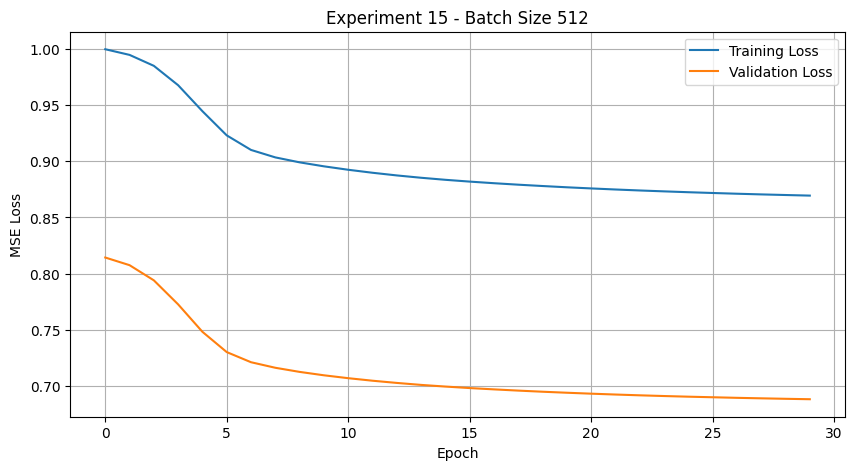

In [95]:
# EXPERIMENT 15 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp15_train_losses,
    label="Training Loss"
)

plt.plot(
    exp15_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 15 - Batch Size 512")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [96]:
# EXPERIMENT 16 - SETUP BATCH SIZE 8

# Set seed for reproducibility
torch.manual_seed(42)

# Create a fresh DNN model
exp16_model = DeepNeuralNetwork(input_size=315)

# Create DataLoader with batch size 8
exp16_train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

# Define loss function
exp16_criterion = nn.MSELoss()

# Define Adam optimizer
exp16_optimizer = optim.Adam(
    exp16_model.parameters(),
    lr=0.00001
)

# Initialize loss lists
exp16_train_losses = []
exp16_val_losses = []

# Number of epochs
exp16_epochs = 30

print("Experiment 16 setup completed!")

Experiment 16 setup completed!


In [97]:
# EXPERIMENT 16 - TRAIN MODEL

for epoch in range(exp16_epochs):

    exp16_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp16_train_loader:

        predictions = exp16_model(X_batch)

        loss = exp16_criterion(predictions, y_batch)

        exp16_optimizer.zero_grad()
        loss.backward()
        exp16_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    train_loss = total_train_loss / len(train_dataset)

    # Validate model
    exp16_model.eval()

    with torch.no_grad():

        val_predictions = exp16_model(X_val_tensor)

        val_loss = exp16_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    exp16_train_losses.append(train_loss)
    exp16_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/30], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

print("Experiment 16 completed!")

Epoch [1/30], Train Loss: 0.9249, Val Loss: 0.7077
Epoch [2/30], Train Loss: 0.8851, Val Loss: 0.6947
Epoch [3/30], Train Loss: 0.8755, Val Loss: 0.6889
Epoch [4/30], Train Loss: 0.8706, Val Loss: 0.6853
Epoch [5/30], Train Loss: 0.8678, Val Loss: 0.6837
Epoch [6/30], Train Loss: 0.8660, Val Loss: 0.6828
Epoch [7/30], Train Loss: 0.8647, Val Loss: 0.6826
Epoch [8/30], Train Loss: 0.8638, Val Loss: 0.6822
Epoch [9/30], Train Loss: 0.8633, Val Loss: 0.6819
Epoch [10/30], Train Loss: 0.8626, Val Loss: 0.6817
Epoch [11/30], Train Loss: 0.8622, Val Loss: 0.6814
Epoch [12/30], Train Loss: 0.8616, Val Loss: 0.6812
Epoch [13/30], Train Loss: 0.8610, Val Loss: 0.6810
Epoch [14/30], Train Loss: 0.8607, Val Loss: 0.6811
Epoch [15/30], Train Loss: 0.8602, Val Loss: 0.6811
Epoch [16/30], Train Loss: 0.8599, Val Loss: 0.6809
Epoch [17/30], Train Loss: 0.8594, Val Loss: 0.6809
Epoch [18/30], Train Loss: 0.8591, Val Loss: 0.6811
Epoch [19/30], Train Loss: 0.8585, Val Loss: 0.6813
Epoch [20/30], Train 

In [98]:
# EXPERIMENT 16 - EVALUATE MODEL

exp16_model.eval()

with torch.no_grad():

    exp16_val_scaled = exp16_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp16_val_predictions = target_scaler.inverse_transform(
        exp16_val_scaled
    )

    # Calculate validation MSE
    exp16_val_mse = mean_squared_error(
        y_val,
        exp16_val_predictions
    )

print("Experiment 16 Validation MSE:", exp16_val_mse)

Experiment 16 Validation MSE: 4510700032.0


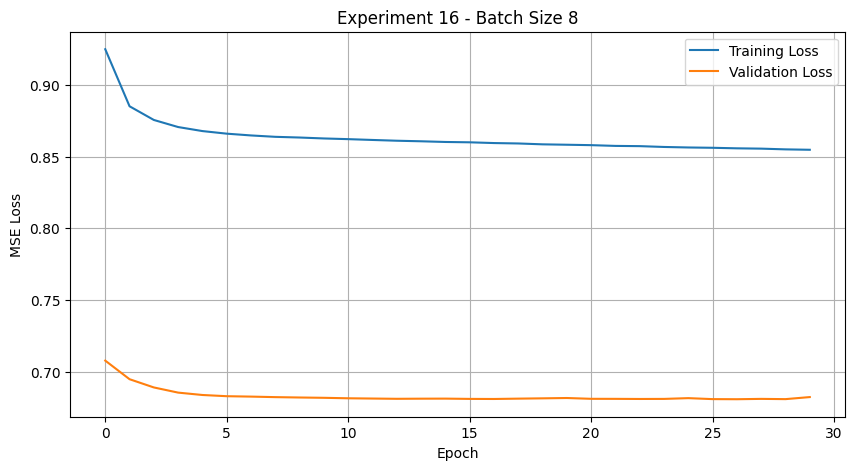

In [99]:
# EXPERIMENT 16 - PLOT TRAINING AND VALIDATION LOSS

plt.figure(figsize=(10, 5))

plt.plot(
    exp16_train_losses,
    label="Training Loss"
)

plt.plot(
    exp16_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 16 - Batch Size 8")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [100]:
#experiment 4:depth=1
#neurons=64
#learning rate=0.01
#create a fresh DNN model
class Experiment4Model(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 64),nn.ReLU(),nn.Linear(64,1))

    def forward(self, x):
        return self.network(x)

#2.create the model
exp4_model = Experiment4Model(input_size=315)
print(exp4_model)

#create a dataloader
exp4_train_loader=DataLoader(train_dataset,batch_size=265,shuffle=True)

#define loss function
exp4_criterion = nn.MSELoss()

#define optimizer
exp4_optimizer = optim.Adam(exp4_model.parameters(), lr=0.01)

#number of epochs
exp4_epochs=30
print("experiment 4 training setup completed!")

#store training and validation losses
exp4_train_losses = []
exp4_val_losses = []

#start training
import time
exp4_start_time = time.time()
for epoch in range(exp4_epochs):
    exp4_model.train()
    total_train_loss = 0
    for X_batch, y_batch in exp4_train_loader:
        predictions = exp4_model(X_batch)
        loss = exp4_criterion(predictions, y_batch)
        exp4_optimizer.zero_grad()
        loss.backward()
        exp4_optimizer.step()
        total_train_loss += loss.item() * X_batch.size(0)

    #calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    #validation
    exp4_model.eval()
    with torch.no_grad():
        val_predictions = exp4_model(X_val_tensor)
        val_loss = exp4_criterion(val_predictions, y_val_tensor).item()

    #save losses
    exp4_train_losses.append(train_loss)
    exp4_val_losses.append(val_loss)

    #display results
    print(f"Epoch [{epoch+1}/{exp4_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    #calculating training time
    exp4_training_time=(time.time() - exp4_start_time)
    print(f"Training time: {exp4_training_time:.2f} seconds")

#display final results
print("Experiment 4 completed!")

print("final training MSE:", exp4_train_losses[-1])
print("final validation MSE:", exp4_val_losses[-1])
print("training time:",round(exp4_training_time, 2), "seconds")

Experiment4Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)
experiment 4 training setup completed!
Epoch [1/30], Train Loss: 0.8789, Val Loss: 0.6878
Training time: 1.65 seconds
Epoch [2/30], Train Loss: 0.8693, Val Loss: 0.6866
Training time: 3.39 seconds
Epoch [3/30], Train Loss: 0.8650, Val Loss: 0.6918
Training time: 5.99 seconds
Epoch [4/30], Train Loss: 0.8610, Val Loss: 0.7009
Training time: 8.42 seconds
Epoch [5/30], Train Loss: 0.8576, Val Loss: 0.6959
Training time: 10.23 seconds
Epoch [6/30], Train Loss: 0.8493, Val Loss: 0.6943
Training time: 12.03 seconds
Epoch [7/30], Train Loss: 0.8394, Val Loss: 0.7241
Training time: 13.91 seconds
Epoch [8/30], Train Loss: 0.8304, Val Loss: 0.7201
Training time: 15.77 seconds
Epoch [9/30], Train Loss: 0.8192, Val Loss: 0.6988
Training time: 17.82 seconds
Epoch [10/30], Train Loss: 0.8081, Val Loss: 0.7115
Training

In [101]:
# EXPERIMENT 17: DEPTH = 1, NEURONS = 64

# 1. Create a fresh DNN model

class Experiment17Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp17_model = Experiment17Model(input_size=315)

print(exp17_model)

Experiment17Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [102]:
# EXPERIMENT 17 - TRAINING SETUP

# Create DataLoader
exp17_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# Define loss function
exp17_criterion = nn.MSELoss()

# Define optimizer
exp17_optimizer = optim.Adam(
    exp17_model.parameters(),
    lr=0.00001
)

# Number of epochs
exp17_epochs = 30

# Store training and validation losses
exp17_train_losses = []
exp17_val_losses = []

print("Experiment 17 training setup completed!")

Experiment 17 training setup completed!


In [103]:
# EXPERIMENT 17 - START TRAINING

import time

exp17_start_time = time.time()

for epoch in range(exp17_epochs):

    exp17_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp17_train_loader:

        predictions = exp17_model(X_batch)

        loss = exp17_criterion(predictions, y_batch)

        exp17_optimizer.zero_grad()
        loss.backward()
        exp17_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp17_model.eval()

    with torch.no_grad():

        val_predictions = exp17_model(X_val_tensor)

        val_loss = exp17_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    exp17_train_losses.append(train_loss)
    exp17_val_losses.append(val_loss)

    # Display results
    print(
        f"Epoch [{epoch+1}/{exp17_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time
exp17_training_time = time.time() - exp17_start_time

print("Experiment 17 completed!")
print("Final training loss:", exp17_train_losses[-1])
print("Final validation loss:", exp17_val_losses[-1])
print("Training time:", round(exp17_training_time, 2), "seconds")

Epoch [1/30], Train Loss: 0.9351, Val Loss: 0.7241
Epoch [2/30], Train Loss: 0.9029, Val Loss: 0.7120
Epoch [3/30], Train Loss: 0.8929, Val Loss: 0.7046
Epoch [4/30], Train Loss: 0.8863, Val Loss: 0.6996
Epoch [5/30], Train Loss: 0.8816, Val Loss: 0.6960
Epoch [6/30], Train Loss: 0.8781, Val Loss: 0.6931
Epoch [7/30], Train Loss: 0.8754, Val Loss: 0.6909
Epoch [8/30], Train Loss: 0.8733, Val Loss: 0.6892
Epoch [9/30], Train Loss: 0.8716, Val Loss: 0.6880
Epoch [10/30], Train Loss: 0.8702, Val Loss: 0.6868
Epoch [11/30], Train Loss: 0.8689, Val Loss: 0.6860
Epoch [12/30], Train Loss: 0.8678, Val Loss: 0.6853
Epoch [13/30], Train Loss: 0.8669, Val Loss: 0.6846
Epoch [14/30], Train Loss: 0.8660, Val Loss: 0.6841
Epoch [15/30], Train Loss: 0.8654, Val Loss: 0.6835
Epoch [16/30], Train Loss: 0.8647, Val Loss: 0.6832
Epoch [17/30], Train Loss: 0.8641, Val Loss: 0.6828
Epoch [18/30], Train Loss: 0.8636, Val Loss: 0.6825
Epoch [19/30], Train Loss: 0.8631, Val Loss: 0.6823
Epoch [20/30], Train 

In [104]:
# EXPERIMENT 17 - EVALUATE MODEL

exp17_model.eval()

with torch.no_grad():

    exp17_val_scaled = exp17_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp17_val_predictions = target_scaler.inverse_transform(
        exp17_val_scaled
    )

    # Calculate validation MSE
    exp17_val_mse = mean_squared_error(
        y_val,
        exp17_val_predictions
    )

print("Experiment 17 Validation MSE:", exp17_val_mse)

Experiment 17 Validation MSE: 4502225920.0


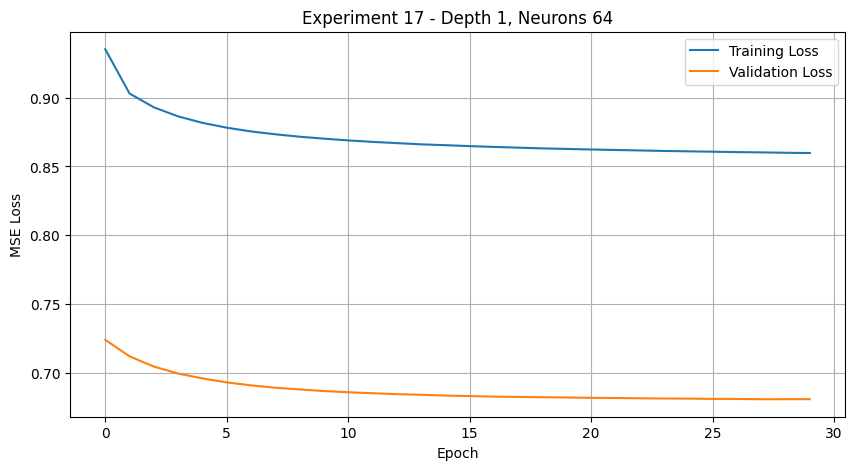

In [105]:
# EXPERIMENT 17 - PLOT LOSS

plt.figure(figsize=(10, 5))

plt.plot(
    exp17_train_losses,
    label="Training Loss"
)

plt.plot(
    exp17_val_losses,
    label="Validation Loss"
)

plt.title("Experiment 17 - Depth 1, Neurons 64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [106]:
# EXPERIMENT 17: INCREASING NETWORK WIDTH
# Learning Rate = 0.00001
# Neurons = 128
# Optimizer = Adam

# 1. Create a fresh DNN model

class Experiment17Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp17_model = Experiment17Model(input_size=315)

print(exp17_model)

Experiment17Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [107]:
# 3. Create DataLoader

exp17_train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

# 4. Define loss function

exp17_criterion = nn.MSELoss()

# 5. Define optimizer (Adam)

exp17_optimizer = optim.Adam(
    exp17_model.parameters(),
    lr=0.00001
)

# 6. Set number of epochs

exp17_epochs = 30

# 7. Store training and validation losses

exp17_train_losses = []
exp17_val_losses = []

print("Experiment 18 training setup completed!")

Experiment 18 training setup completed!


In [108]:
# EXPERIMENT 17 - START TRAINING

import time

exp17_start_time = time.time()

for epoch in range(exp17_epochs):

    exp17_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp17_train_loader:

        predictions = exp17_model(X_batch)

        loss = exp17_criterion(predictions, y_batch)

        exp17_optimizer.zero_grad()
        loss.backward()
        exp17_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp17_model.eval()

    with torch.no_grad():

        val_predictions = exp17_model(X_val_tensor)

        val_loss = exp17_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    exp17_train_losses.append(train_loss)
    exp17_val_losses.append(val_loss)

    # Display results
    print(
        f"Epoch [{epoch+1}/{exp17_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time
exp17_training_time = time.time() - exp17_start_time

print("Experiment 17 completed!")
print("Final training loss:", exp17_train_losses[-1])
print("Final validation loss:", exp17_val_losses[-1])
print("Training time:", round(exp17_training_time, 2), "seconds")

Epoch [1/30], Train Loss: 0.9903, Val Loss: 0.7890
Epoch [2/30], Train Loss: 0.9442, Val Loss: 0.7333
Epoch [3/30], Train Loss: 0.9075, Val Loss: 0.7155
Epoch [4/30], Train Loss: 0.8972, Val Loss: 0.7091
Epoch [5/30], Train Loss: 0.8914, Val Loss: 0.7046
Epoch [6/30], Train Loss: 0.8869, Val Loss: 0.7011
Epoch [7/30], Train Loss: 0.8833, Val Loss: 0.6983
Epoch [8/30], Train Loss: 0.8803, Val Loss: 0.6959
Epoch [9/30], Train Loss: 0.8776, Val Loss: 0.6940
Epoch [10/30], Train Loss: 0.8754, Val Loss: 0.6922
Epoch [11/30], Train Loss: 0.8734, Val Loss: 0.6905
Epoch [12/30], Train Loss: 0.8718, Val Loss: 0.6892
Epoch [13/30], Train Loss: 0.8702, Val Loss: 0.6880
Epoch [14/30], Train Loss: 0.8689, Val Loss: 0.6870
Epoch [15/30], Train Loss: 0.8677, Val Loss: 0.6863
Epoch [16/30], Train Loss: 0.8666, Val Loss: 0.6855
Epoch [17/30], Train Loss: 0.8657, Val Loss: 0.6848
Epoch [18/30], Train Loss: 0.8648, Val Loss: 0.6844
Epoch [19/30], Train Loss: 0.8640, Val Loss: 0.6837
Epoch [20/30], Train 

In [109]:
# EXPERIMENT 17 - EVALUATE MODEL

exp17_model.eval()

with torch.no_grad():

    exp17_val_scaled = exp17_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp17_val_predictions = target_scaler.inverse_transform(
        exp17_val_scaled
    )

    # Calculate validation MSE

    exp17_val_mse = mean_squared_error(
        y_val,
        exp17_val_predictions
    )

print("Experiment 17 Validation MSE:", exp17_val_mse)

Experiment 17 Validation MSE: 4507074560.0


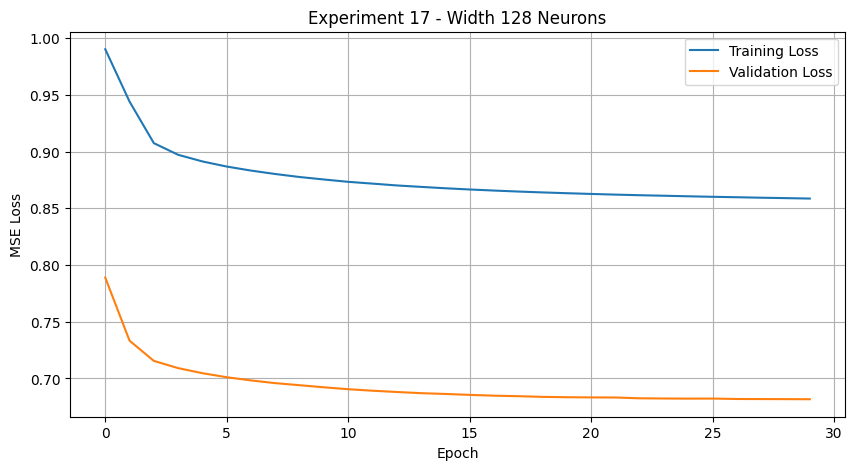

In [111]:
# EXPERIMENT 17- PLOT TRAINING AND VALIDATION LOSS

plt.figure(figsize=(10, 5))

plt.plot(exp17_train_losses, label="Training Loss")
plt.plot(exp17_val_losses, label="Validation Loss")

plt.title("Experiment 17 - Width 128 Neurons")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [112]:
# EXPERIMENT 18 - DECREASING NETWORK WIDTH
# Neurons = 32
# Learning Rate = 0.00001

# 1. Create a fresh DNN model

class Experiment18Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp18_model = Experiment18Model(input_size=315)

print(exp18_model)

Experiment18Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [113]:
# 3. Create DataLoader

exp18_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# 4. Define loss function

exp18_criterion = nn.MSELoss()

# 5. Define optimizer

exp18_optimizer = optim.Adam(
    exp18_model.parameters(),
    lr=0.00001
)

# 6. Set number of epochs

exp18_epochs = 30

print("Experiment 18 training setup completed!")

# 7. Store training and validation losses

exp18_train_losses = []
exp18_val_losses = []

Experiment 18 training setup completed!


In [114]:
# 8. Start training

import time

exp18_start_time = time.time()

for epoch in range(exp18_epochs):

    exp18_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp18_train_loader:

        predictions = exp18_model(X_batch)

        loss = exp18_criterion(predictions, y_batch)

        exp18_optimizer.zero_grad()
        loss.backward()
        exp18_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # 9. Validation

    exp18_model.eval()

    with torch.no_grad():

        val_predictions = exp18_model(X_val_tensor)

        val_loss = exp18_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # 10. Save losses

    exp18_train_losses.append(train_loss)
    exp18_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp18_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# 11. Calculate training time

exp18_training_time = time.time() - exp18_start_time

print(f"Training time: {exp18_training_time:.2f} seconds")

# 12. Display final results

print("Experiment 18 completed!")

print("Final training MSE:", exp18_train_losses[-1])
print("Final validation MSE:", exp18_val_losses[-1])

print(
    "Training time:",
    round(exp18_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.9701, Val Loss: 0.7392
Epoch [2/30], Train Loss: 0.9110, Val Loss: 0.7171
Epoch [3/30], Train Loss: 0.8966, Val Loss: 0.7069
Epoch [4/30], Train Loss: 0.8873, Val Loss: 0.6999
Epoch [5/30], Train Loss: 0.8814, Val Loss: 0.6956
Epoch [6/30], Train Loss: 0.8774, Val Loss: 0.6925
Epoch [7/30], Train Loss: 0.8744, Val Loss: 0.6901
Epoch [8/30], Train Loss: 0.8721, Val Loss: 0.6885
Epoch [9/30], Train Loss: 0.8703, Val Loss: 0.6870
Epoch [10/30], Train Loss: 0.8690, Val Loss: 0.6860
Epoch [11/30], Train Loss: 0.8679, Val Loss: 0.6853
Epoch [12/30], Train Loss: 0.8670, Val Loss: 0.6849
Epoch [13/30], Train Loss: 0.8663, Val Loss: 0.6843
Epoch [14/30], Train Loss: 0.8657, Val Loss: 0.6840
Epoch [15/30], Train Loss: 0.8652, Val Loss: 0.6838
Epoch [16/30], Train Loss: 0.8647, Val Loss: 0.6837
Epoch [17/30], Train Loss: 0.8644, Val Loss: 0.6836
Epoch [18/30], Train Loss: 0.8640, Val Loss: 0.6835
Epoch [19/30], Train Loss: 0.8637, Val Loss: 0.6836
Epoch [20/30], Train 

In [ ]:
# EXPERIMENT 18 - EVALUATE MODEL

exp18_model.eval()

with torch.no_grad():

    exp18_val_scaled = exp18_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp18_val_predictions = target_scaler.inverse_transform(
        exp18_val_scaled
    )

    # Calculate validation MSE

    exp18_val_mse = mean_squared_error(
        y_val,
        exp18_val_predictions
    )

print("Experiment 18 Validation MSE:", exp18_val_mse)

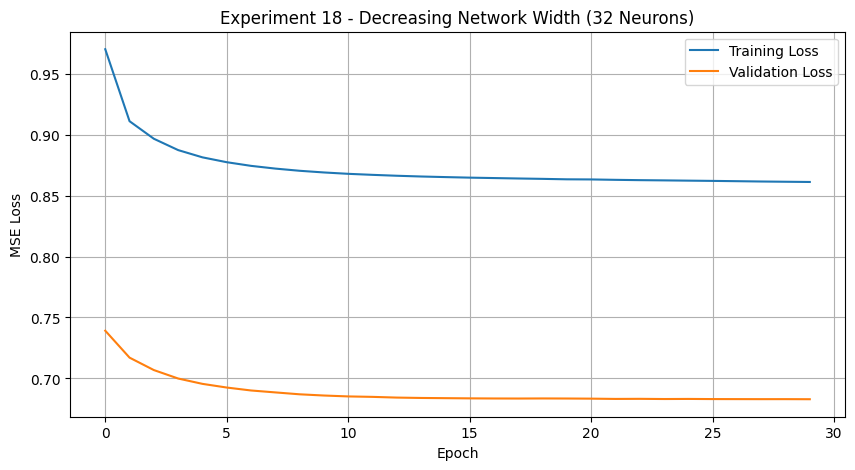

In [115]:
# EXPERIMENT 18 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(exp18_train_losses, label="Training Loss")
plt.plot(exp18_val_losses, label="Validation Loss")

plt.title("Experiment 18 - Decreasing Network Width (32 Neurons)")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [116]:
# EXPERIMENT 19 - NETWORK WIDTH = 16
# Learning Rate = 0.00001
# Optimizer = Adam

# 1. Create a fresh DNN model

class Experiment19Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp19_model = Experiment19Model(input_size=315)

print(exp19_model)

Experiment19Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [117]:
# 3. Create DataLoader

exp19_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# 4. Define loss function

exp19_criterion = nn.MSELoss()

# 5. Define optimizer

exp19_optimizer = optim.Adam(
    exp19_model.parameters(),
    lr=0.00001
)

# 6. Set number of epochs

exp19_epochs = 30

# 7. Store training and validation losses

exp19_train_losses = []
exp19_val_losses = []

print("Experiment 19 training setup completed!")

Experiment 19 training setup completed!


In [118]:
# 8. Start training

import time

exp19_start_time = time.time()

for epoch in range(exp19_epochs):

    exp19_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp19_train_loader:

        predictions = exp19_model(X_batch)

        loss = exp19_criterion(predictions, y_batch)

        exp19_optimizer.zero_grad()
        loss.backward()
        exp19_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # 9. Validation

    exp19_model.eval()

    with torch.no_grad():

        val_predictions = exp19_model(X_val_tensor)

        val_loss = exp19_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # 10. Save losses

    exp19_train_losses.append(train_loss)
    exp19_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp19_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# 11. Calculate training time

exp19_training_time = time.time() - exp19_start_time

print(f"Training time: {exp19_training_time:.2f} seconds")

# 12. Display final results

print("Experiment 19 completed!")

print("Final training MSE:", exp19_train_losses[-1])
print("Final validation MSE:", exp19_val_losses[-1])

print(
    "Training time:",
    round(exp19_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 1.0260, Val Loss: 0.7970
Epoch [2/30], Train Loss: 0.9463, Val Loss: 0.7369
Epoch [3/30], Train Loss: 0.9119, Val Loss: 0.7197
Epoch [4/30], Train Loss: 0.9007, Val Loss: 0.7119
Epoch [5/30], Train Loss: 0.8942, Val Loss: 0.7070
Epoch [6/30], Train Loss: 0.8896, Val Loss: 0.7032
Epoch [7/30], Train Loss: 0.8860, Val Loss: 0.7003
Epoch [8/30], Train Loss: 0.8830, Val Loss: 0.6978
Epoch [9/30], Train Loss: 0.8805, Val Loss: 0.6956
Epoch [10/30], Train Loss: 0.8784, Val Loss: 0.6938
Epoch [11/30], Train Loss: 0.8765, Val Loss: 0.6922
Epoch [12/30], Train Loss: 0.8749, Val Loss: 0.6909
Epoch [13/30], Train Loss: 0.8735, Val Loss: 0.6898
Epoch [14/30], Train Loss: 0.8724, Val Loss: 0.6888
Epoch [15/30], Train Loss: 0.8713, Val Loss: 0.6880
Epoch [16/30], Train Loss: 0.8705, Val Loss: 0.6873
Epoch [17/30], Train Loss: 0.8696, Val Loss: 0.6867
Epoch [18/30], Train Loss: 0.8689, Val Loss: 0.6862
Epoch [19/30], Train Loss: 0.8683, Val Loss: 0.6857
Epoch [20/30], Train 

In [119]:
# EXPERIMENT 19 - EVALUATE MODEL

exp19_model.eval()

with torch.no_grad():

    exp19_val_scaled = exp19_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp19_val_predictions = target_scaler.inverse_transform(
        exp19_val_scaled
    )

    # Calculate validation MSE

    exp19_val_mse = mean_squared_error(
        y_val,
        exp19_val_predictions
    )

print("Experiment 19 Validation MSE:", exp19_val_mse)

Experiment 19 Validation MSE: 4520349696.0


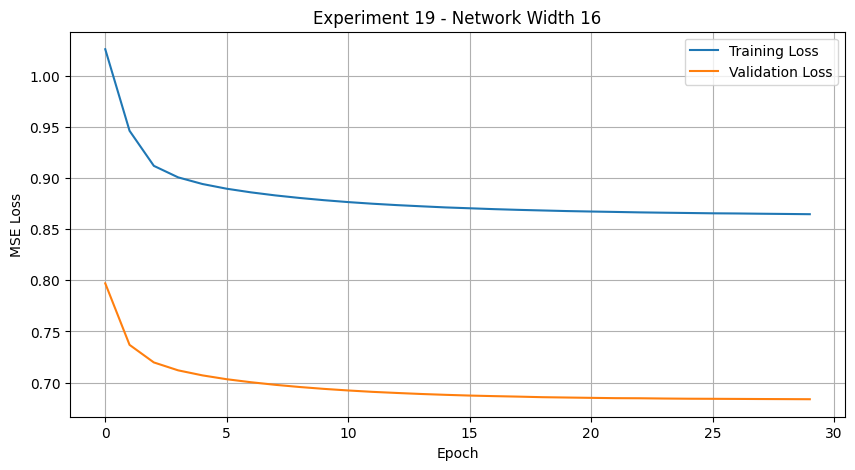

In [120]:
# EXPERIMENT 19 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(exp19_train_losses, label="Training Loss")
plt.plot(exp19_val_losses, label="Validation Loss")

plt.title("Experiment 19 - Network Width 16")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [121]:
# EXPERIMENT 20 - NETWORK WIDTH 64

# 1. Create a fresh DNN model

class Experiment20Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp20_model = Experiment20Model(input_size=315)

print(exp20_model)

Experiment20Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [122]:
# 3. Create DataLoader

exp20_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# 4. Define loss function

exp20_criterion = nn.MSELoss()

# 5. Define optimizer

exp20_optimizer = optim.Adam(
    exp20_model.parameters(),
    lr=0.00001
)

# 6. Set number of epochs

exp20_epochs = 30

# 7. Store training and validation losses

exp20_train_losses = []
exp20_val_losses = []

print("Experiment 20 training setup completed!")

Experiment 20 training setup completed!


In [123]:
# 8. Start training

import time

exp20_start_time = time.time()

for epoch in range(exp20_epochs):

    exp20_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp20_train_loader:

        predictions = exp20_model(X_batch)

        loss = exp20_criterion(predictions, y_batch)

        exp20_optimizer.zero_grad()
        loss.backward()
        exp20_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # 9. Validation

    exp20_model.eval()

    with torch.no_grad():

        val_predictions = exp20_model(X_val_tensor)

        val_loss = exp20_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # 10. Save losses

    exp20_train_losses.append(train_loss)
    exp20_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp20_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# 11. Calculate training time

exp20_training_time = time.time() - exp20_start_time

print(f"Training time: {exp20_training_time:.2f} seconds")

# 12. Display final results

print("Experiment 20 completed!")

print("Final training MSE:", exp20_train_losses[-1])
print("Final validation MSE:", exp20_val_losses[-1])

print(
    "Training time:",
    round(exp20_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.9396, Val Loss: 0.7213
Epoch [2/30], Train Loss: 0.8971, Val Loss: 0.7059
Epoch [3/30], Train Loss: 0.8851, Val Loss: 0.6973
Epoch [4/30], Train Loss: 0.8779, Val Loss: 0.6922
Epoch [5/30], Train Loss: 0.8733, Val Loss: 0.6885
Epoch [6/30], Train Loss: 0.8701, Val Loss: 0.6862
Epoch [7/30], Train Loss: 0.8678, Val Loss: 0.6848
Epoch [8/30], Train Loss: 0.8663, Val Loss: 0.6838
Epoch [9/30], Train Loss: 0.8652, Val Loss: 0.6831
Epoch [10/30], Train Loss: 0.8642, Val Loss: 0.6829
Epoch [11/30], Train Loss: 0.8635, Val Loss: 0.6833
Epoch [12/30], Train Loss: 0.8630, Val Loss: 0.6826
Epoch [13/30], Train Loss: 0.8625, Val Loss: 0.6822
Epoch [14/30], Train Loss: 0.8620, Val Loss: 0.6820
Epoch [15/30], Train Loss: 0.8616, Val Loss: 0.6818
Epoch [16/30], Train Loss: 0.8611, Val Loss: 0.6816
Epoch [17/30], Train Loss: 0.8608, Val Loss: 0.6817
Epoch [18/30], Train Loss: 0.8604, Val Loss: 0.6815
Epoch [19/30], Train Loss: 0.8601, Val Loss: 0.6815
Epoch [20/30], Train 

In [126]:
# EXPERIMENT 20 - EVALUATE MODEL

exp20_model.eval()

with torch.no_grad():

    exp20_val_scaled = exp20_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp20_val_predictions = target_scaler.inverse_transform(
        exp20_val_scaled
    )

    # Calculate validation MSE

    exp20_val_mse = mean_squared_error(
        y_val,
        exp20_val_predictions
    )

print("Experiment 20 Validation MSE:", exp20_val_mse)

Experiment 20 Validation MSE: 4502965248.0


In [124]:
# EXPERIMENT 21 - DEPTH = 1, NEURONS = 64

# 1. Create a fresh DNN model

class Experiment21Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp21_model = Experiment21Model(input_size=315)

print(exp21_model)

Experiment21Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [125]:
# 3. Create DataLoader

exp21_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# 4. Define loss function

exp21_criterion = nn.MSELoss()

# 5. Define optimizer

exp21_optimizer = optim.Adam(
    exp21_model.parameters(),
    lr=0.00001
)

# 6. Set number of epochs

exp21_epochs = 30

# 7. Store training and validation losses

exp21_train_losses = []
exp21_val_losses = []

print("Experiment 21 training setup completed!")

Experiment 21 training setup completed!


In [127]:
# 8. Start training

import time

exp21_start_time = time.time()

for epoch in range(exp21_epochs):

    exp21_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp21_train_loader:

        predictions = exp21_model(X_batch)

        loss = exp21_criterion(predictions, y_batch)

        exp21_optimizer.zero_grad()
        loss.backward()
        exp21_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # 9. Validation

    exp21_model.eval()

    with torch.no_grad():

        val_predictions = exp21_model(X_val_tensor)

        val_loss = exp21_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # 10. Save losses

    exp21_train_losses.append(train_loss)
    exp21_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp21_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# 11. Calculate training time

exp21_training_time = time.time() - exp21_start_time

print(f"Training time: {exp21_training_time:.2f} seconds")

# 12. Display final results

print("Experiment 21 completed!")

print("Final training MSE:", exp21_train_losses[-1])
print("Final validation MSE:", exp21_val_losses[-1])

print(
    "Training time:",
    round(exp21_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.9424, Val Loss: 0.7267
Epoch [2/30], Train Loss: 0.9041, Val Loss: 0.7136
Epoch [3/30], Train Loss: 0.8934, Val Loss: 0.7057
Epoch [4/30], Train Loss: 0.8865, Val Loss: 0.7004
Epoch [5/30], Train Loss: 0.8817, Val Loss: 0.6969
Epoch [6/30], Train Loss: 0.8782, Val Loss: 0.6939
Epoch [7/30], Train Loss: 0.8755, Val Loss: 0.6918
Epoch [8/30], Train Loss: 0.8735, Val Loss: 0.6901
Epoch [9/30], Train Loss: 0.8718, Val Loss: 0.6888
Epoch [10/30], Train Loss: 0.8704, Val Loss: 0.6877
Epoch [11/30], Train Loss: 0.8692, Val Loss: 0.6868
Epoch [12/30], Train Loss: 0.8682, Val Loss: 0.6860
Epoch [13/30], Train Loss: 0.8673, Val Loss: 0.6854
Epoch [14/30], Train Loss: 0.8665, Val Loss: 0.6848
Epoch [15/30], Train Loss: 0.8658, Val Loss: 0.6842
Epoch [16/30], Train Loss: 0.8651, Val Loss: 0.6838
Epoch [17/30], Train Loss: 0.8646, Val Loss: 0.6835
Epoch [18/30], Train Loss: 0.8641, Val Loss: 0.6832
Epoch [19/30], Train Loss: 0.8636, Val Loss: 0.6829
Epoch [20/30], Train 

In [128]:
# EXPERIMENT 21 - EVALUATE MODEL

exp21_model.eval()

with torch.no_grad():

    exp21_val_scaled = exp21_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp21_val_predictions = target_scaler.inverse_transform(
        exp21_val_scaled
    )

    # Calculate validation MSE

    exp21_val_mse = mean_squared_error(
        y_val,
        exp21_val_predictions
    )

print("Experiment 21 Validation MSE:", exp21_val_mse)

Experiment 21 Validation MSE: 4504003072.0


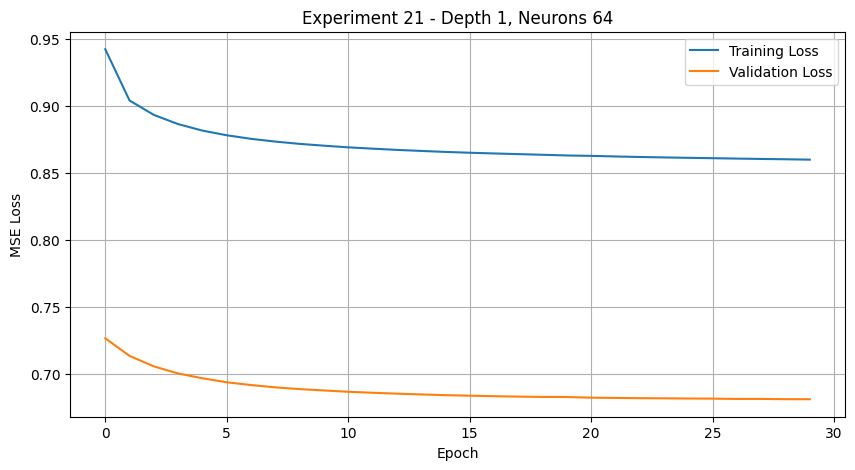

In [129]:
# EXPERIMENT 21 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(exp21_train_losses, label="Training Loss")
plt.plot(exp21_val_losses, label="Validation Loss")

plt.title("Experiment 21 - Depth 1, Neurons 64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [130]:
# EXPERIMENT 22 - DEPTH = 2, NEURONS = 64

# 1. Create a fresh DNN model

class Experiment22Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# 2. Create the model

exp22_model = Experiment22Model(input_size=315)

print(exp22_model)

Experiment22Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [131]:
# 3. Create DataLoader

exp22_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# 4. Define loss function

exp22_criterion = nn.MSELoss()

# 5. Define optimizer

exp22_optimizer = optim.Adam(
    exp22_model.parameters(),
    lr=0.00001
)

# 6. Set number of epochs

exp22_epochs = 30

# 7. Store training and validation losses

exp22_train_losses = []
exp22_val_losses = []

print("Experiment 22 training setup completed!")

Experiment 22 training setup completed!


In [134]:
# 8. Start training

import time

exp22_start_time = time.time()

for epoch in range(exp22_epochs):

    exp22_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp22_train_loader:

        predictions = exp22_model(X_batch)

        loss = exp22_criterion(predictions, y_batch)

        exp22_optimizer.zero_grad()
        loss.backward()
        exp22_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # 9. Validation

    exp22_model.eval()

    with torch.no_grad():

        val_predictions = exp22_model(X_val_tensor)

        val_loss = exp22_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # 10. Save losses

    exp22_train_losses.append(train_loss)
    exp22_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp22_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# 11. Calculate training time

exp22_training_time = time.time() - exp22_start_time

print(f"Training time: {exp22_training_time:.2f} seconds")

# 12. Display final results

print("Experiment 22 completed!")

print("Final training MSE:", exp22_train_losses[-1])
print("Final validation MSE:", exp22_val_losses[-1])

print(
    "Training time:",
    round(exp22_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.9407, Val Loss: 0.7249
Epoch [2/30], Train Loss: 0.9012, Val Loss: 0.7084
Epoch [3/30], Train Loss: 0.8881, Val Loss: 0.6995
Epoch [4/30], Train Loss: 0.8808, Val Loss: 0.6942
Epoch [5/30], Train Loss: 0.8760, Val Loss: 0.6906
Epoch [6/30], Train Loss: 0.8727, Val Loss: 0.6881
Epoch [7/30], Train Loss: 0.8701, Val Loss: 0.6862
Epoch [8/30], Train Loss: 0.8682, Val Loss: 0.6849
Epoch [9/30], Train Loss: 0.8666, Val Loss: 0.6837
Epoch [10/30], Train Loss: 0.8653, Val Loss: 0.6830
Epoch [11/30], Train Loss: 0.8643, Val Loss: 0.6828
Epoch [12/30], Train Loss: 0.8635, Val Loss: 0.6819
Epoch [13/30], Train Loss: 0.8629, Val Loss: 0.6816
Epoch [14/30], Train Loss: 0.8623, Val Loss: 0.6814
Epoch [15/30], Train Loss: 0.8618, Val Loss: 0.6810
Epoch [16/30], Train Loss: 0.8613, Val Loss: 0.6809
Epoch [17/30], Train Loss: 0.8608, Val Loss: 0.6812
Epoch [18/30], Train Loss: 0.8606, Val Loss: 0.6809
Epoch [19/30], Train Loss: 0.8601, Val Loss: 0.6806
Epoch [20/30], Train 

In [135]:
# EXPERIMENT 22 - EVALUATE MODEL

exp22_model.eval()

with torch.no_grad():

    exp22_val_scaled = exp22_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp22_val_predictions = target_scaler.inverse_transform(
        exp22_val_scaled
    )

    # Calculate validation MSE

    exp22_val_mse = mean_squared_error(
        y_val,
        exp22_val_predictions
    )

print("Experiment 22 Validation MSE:", exp22_val_mse)

Experiment 22 Validation MSE: 4498168320.0


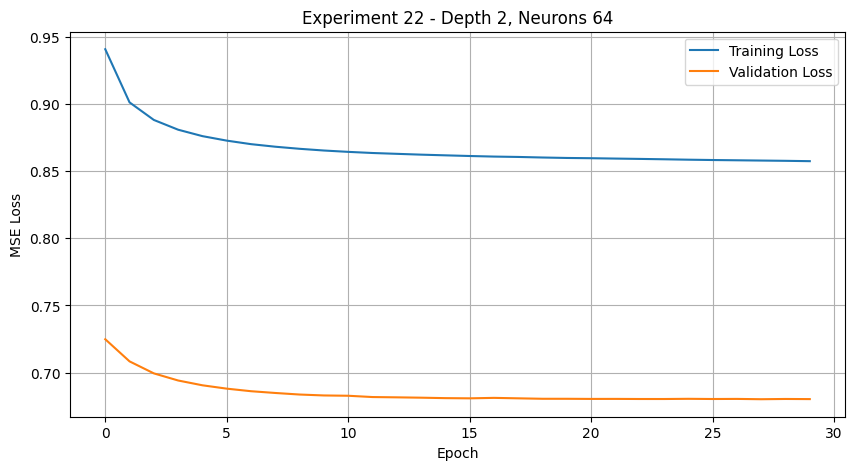

In [139]:
# EXPERIMENT 22 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(exp22_train_losses, label="Training Loss")
plt.plot(exp22_val_losses, label="Validation Loss")

plt.title("Experiment 22 - Depth 2, Neurons 64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [136]:
# EXPERIMENT 23 - DEPTH = 3, NEURONS = 64

# 1. Create a fresh DNN model

class Experiment23Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp23_model = Experiment23Model(input_size=315)

print(exp23_model)

Experiment23Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [137]:
# EXPERIMENT 23 - TRAINING SETUP

# Create DataLoader
exp23_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# Define loss function
exp23_criterion = nn.MSELoss()

# Define optimizer
exp23_optimizer = optim.Adam(
    exp23_model.parameters(),
    lr=0.00001
)

# Number of epochs
exp23_epochs = 30

# Store training and validation losses
exp23_train_losses = []
exp23_val_losses = []

print("Experiment 23 training setup completed!")

Experiment 23 training setup completed!


In [138]:
# EXPERIMENT 23 - START TRAINING

import time

exp23_start_time = time.time()

for epoch in range(exp23_epochs):

    exp23_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp23_train_loader:

        predictions = exp23_model(X_batch)

        loss = exp23_criterion(predictions, y_batch)

        exp23_optimizer.zero_grad()
        loss.backward()
        exp23_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validation
    exp23_model.eval()

    with torch.no_grad():

        val_predictions = exp23_model(X_val_tensor)

        val_loss = exp23_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses
    exp23_train_losses.append(train_loss)
    exp23_val_losses.append(val_loss)

    # Display results
    print(
        f"Epoch [{epoch+1}/{exp23_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time
exp23_training_time = time.time() - exp23_start_time

print(f"Training time: {exp23_training_time:.2f} seconds")

# Display final results
print("Experiment 23 completed!")

print("Final training MSE:", exp23_train_losses[-1])
print("Final validation MSE:", exp23_val_losses[-1])

print(
    "Training time:",
    round(exp23_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.9424, Val Loss: 0.7183
Epoch [2/30], Train Loss: 0.8959, Val Loss: 0.7047
Epoch [3/30], Train Loss: 0.8849, Val Loss: 0.6971
Epoch [4/30], Train Loss: 0.8782, Val Loss: 0.6920
Epoch [5/30], Train Loss: 0.8738, Val Loss: 0.6887
Epoch [6/30], Train Loss: 0.8706, Val Loss: 0.6863
Epoch [7/30], Train Loss: 0.8682, Val Loss: 0.6843
Epoch [8/30], Train Loss: 0.8665, Val Loss: 0.6833
Epoch [9/30], Train Loss: 0.8652, Val Loss: 0.6825
Epoch [10/30], Train Loss: 0.8640, Val Loss: 0.6825
Epoch [11/30], Train Loss: 0.8634, Val Loss: 0.6818
Epoch [12/30], Train Loss: 0.8626, Val Loss: 0.6814
Epoch [13/30], Train Loss: 0.8620, Val Loss: 0.6814
Epoch [14/30], Train Loss: 0.8614, Val Loss: 0.6811
Epoch [15/30], Train Loss: 0.8608, Val Loss: 0.6813
Epoch [16/30], Train Loss: 0.8603, Val Loss: 0.6808
Epoch [17/30], Train Loss: 0.8599, Val Loss: 0.6808
Epoch [18/30], Train Loss: 0.8595, Val Loss: 0.6806
Epoch [19/30], Train Loss: 0.8591, Val Loss: 0.6805
Epoch [20/30], Train 

In [140]:
# EXPERIMENT 23 - EVALUATE MODEL

exp23_model.eval()

with torch.no_grad():

    exp23_val_scaled = exp23_model(X_val_tensor).numpy()

    # Convert predictions to original price scale
    exp23_val_predictions = target_scaler.inverse_transform(
        exp23_val_scaled
    )

    # Calculate validation MSE
    exp23_val_mse = mean_squared_error(
        y_val,
        exp23_val_predictions
    )

print("Experiment 23 Validation MSE:", exp23_val_mse)

Experiment 23 Validation MSE: 4497785856.0


In [141]:
# EXPERIMENT 24 - DEPTH = 4, WIDTH = 64

# 1. Create a fresh DNN model

class Experiment24Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp24_model = Experiment24Model(input_size=315)

print(exp24_model)

Experiment24Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): ReLU()
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [142]:
# 2. Create DataLoader

exp24_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# 3. Define loss function

exp24_criterion = nn.MSELoss()

# 4. Define optimizer

exp24_optimizer = optim.Adam(
    exp24_model.parameters(),
    lr=0.00001
)

# 5. Set number of epochs

exp24_epochs = 30

# Store training and validation losses

exp24_train_losses = []
exp24_val_losses = []

print("Experiment 24 training setup completed!")

Experiment 24 training setup completed!


In [143]:
# 6. Start training

import time

exp24_start_time = time.time()

for epoch in range(exp24_epochs):

    exp24_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp24_train_loader:

        predictions = exp24_model(X_batch)

        loss = exp24_criterion(predictions, y_batch)

        exp24_optimizer.zero_grad()
        loss.backward()
        exp24_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp24_model.eval()

    with torch.no_grad():

        val_predictions = exp24_model(X_val_tensor)

        val_loss = exp24_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp24_train_losses.append(train_loss)
    exp24_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp24_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp24_training_time = time.time() - exp24_start_time

print(f"Training time: {exp24_training_time:.2f} seconds")

# Display final results

print("Experiment 24 completed!")

print("Final training MSE:", exp24_train_losses[-1])
print("Final validation MSE:", exp24_val_losses[-1])

print(
    "Training time:",
    round(exp24_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.9429, Val Loss: 0.7192
Epoch [2/30], Train Loss: 0.8947, Val Loss: 0.7018
Epoch [3/30], Train Loss: 0.8817, Val Loss: 0.6935
Epoch [4/30], Train Loss: 0.8749, Val Loss: 0.6888
Epoch [5/30], Train Loss: 0.8705, Val Loss: 0.6860
Epoch [6/30], Train Loss: 0.8677, Val Loss: 0.6840
Epoch [7/30], Train Loss: 0.8657, Val Loss: 0.6829
Epoch [8/30], Train Loss: 0.8643, Val Loss: 0.6824
Epoch [9/30], Train Loss: 0.8634, Val Loss: 0.6819
Epoch [10/30], Train Loss: 0.8625, Val Loss: 0.6821
Epoch [11/30], Train Loss: 0.8618, Val Loss: 0.6814
Epoch [12/30], Train Loss: 0.8613, Val Loss: 0.6814
Epoch [13/30], Train Loss: 0.8609, Val Loss: 0.6812
Epoch [14/30], Train Loss: 0.8605, Val Loss: 0.6816
Epoch [15/30], Train Loss: 0.8599, Val Loss: 0.6813
Epoch [16/30], Train Loss: 0.8595, Val Loss: 0.6813
Epoch [17/30], Train Loss: 0.8592, Val Loss: 0.6819
Epoch [18/30], Train Loss: 0.8588, Val Loss: 0.6812
Epoch [19/30], Train Loss: 0.8585, Val Loss: 0.6814
Epoch [20/30], Train 

In [144]:
# EXPERIMENT 24 - EVALUATE MODEL

exp24_model.eval()

with torch.no_grad():

    exp24_val_scaled = exp24_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp24_val_predictions = target_scaler.inverse_transform(
        exp24_val_scaled
    )

    # Calculate validation MSE

    exp24_val_mse = mean_squared_error(
        y_val,
        exp24_val_predictions
    )

print("Experiment 24 Validation MSE:", exp24_val_mse)

Experiment 24 Validation MSE: 4502548992.0


In [145]:
# EXPERIMENT 25 - MSE LOSS
# Hidden Layers = 2
# Neurons = 64

# 1. Create a fresh DNN model

class Experiment25Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp25_model = Experiment25Model(input_size=315)

print(exp25_model)

Experiment25Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [147]:
# EXPERIMENT 25 - TRAINING SETUP

# Create DataLoader

exp25_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# Define loss function

exp25_criterion = nn.MSELoss()

# Define optimizer

exp25_optimizer = optim.Adam(
    exp25_model.parameters(),
    lr=0.00001
)

# Number of epochs

exp25_epochs = 30

# Store training and validation losses

exp25_train_losses = []
exp25_val_losses = []

print("Experiment 25 training setup completed!")

Experiment 25 training setup completed!


In [148]:
# EXPERIMENT 25 - START TRAINING

import time

exp25_start_time = time.time()

for epoch in range(exp25_epochs):

    exp25_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp25_train_loader:

        predictions = exp25_model(X_batch)

        loss = exp25_criterion(predictions, y_batch)

        exp25_optimizer.zero_grad()
        loss.backward()
        exp25_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp25_model.eval()

    with torch.no_grad():

        val_predictions = exp25_model(X_val_tensor)

        val_loss = exp25_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp25_train_losses.append(train_loss)
    exp25_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp25_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp25_training_time = time.time() - exp25_start_time

print(f"Training time: {exp25_training_time:.2f} seconds")

# Display final results

print("Experiment 25 completed!")

print("Final training MSE:", exp25_train_losses[-1])
print("Final validation MSE:", exp25_val_losses[-1])

print(
    "Training time:",
    round(exp25_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.9445, Val Loss: 0.7208
Epoch [2/30], Train Loss: 0.8982, Val Loss: 0.7066
Epoch [3/30], Train Loss: 0.8871, Val Loss: 0.6989
Epoch [4/30], Train Loss: 0.8804, Val Loss: 0.6940
Epoch [5/30], Train Loss: 0.8760, Val Loss: 0.6907
Epoch [6/30], Train Loss: 0.8729, Val Loss: 0.6884
Epoch [7/30], Train Loss: 0.8705, Val Loss: 0.6865
Epoch [8/30], Train Loss: 0.8685, Val Loss: 0.6856
Epoch [9/30], Train Loss: 0.8670, Val Loss: 0.6841
Epoch [10/30], Train Loss: 0.8658, Val Loss: 0.6834
Epoch [11/30], Train Loss: 0.8649, Val Loss: 0.6827
Epoch [12/30], Train Loss: 0.8639, Val Loss: 0.6822
Epoch [13/30], Train Loss: 0.8633, Val Loss: 0.6818
Epoch [14/30], Train Loss: 0.8626, Val Loss: 0.6816
Epoch [15/30], Train Loss: 0.8622, Val Loss: 0.6814
Epoch [16/30], Train Loss: 0.8617, Val Loss: 0.6812
Epoch [17/30], Train Loss: 0.8612, Val Loss: 0.6812
Epoch [18/30], Train Loss: 0.8608, Val Loss: 0.6811
Epoch [19/30], Train Loss: 0.8605, Val Loss: 0.6809
Epoch [20/30], Train 

In [149]:
# EXPERIMENT 25 - EVALUATE MODEL

exp25_model.eval()

with torch.no_grad():

    exp25_val_scaled = exp25_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp25_val_predictions = target_scaler.inverse_transform(
        exp25_val_scaled
    )

    # Calculate validation MSE

    exp25_val_mse = mean_squared_error(
        y_val,
        exp25_val_predictions
    )

print("Experiment 25 Validation MSE:", exp25_val_mse)

Experiment 25 Validation MSE: 4499769856.0


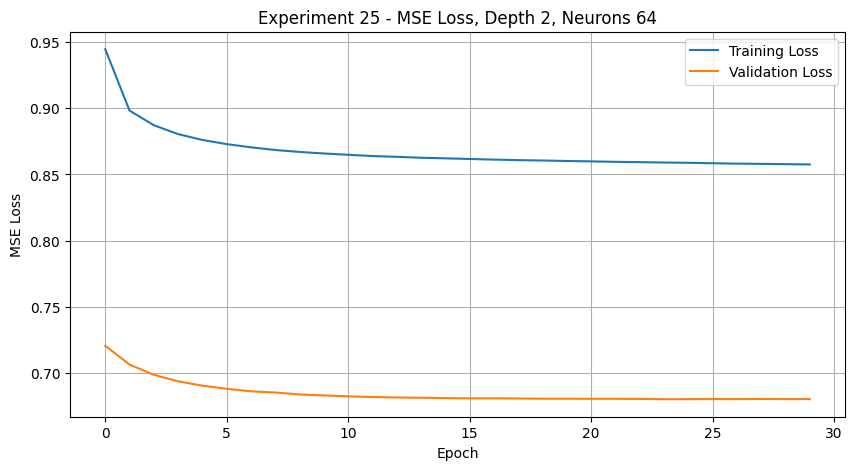

In [150]:
# EXPERIMENT 25 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(exp25_train_losses, label="Training Loss")
plt.plot(exp25_val_losses, label="Validation Loss")

plt.title("Experiment 25 - MSE Loss, Depth 2, Neurons 64")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)

plt.show()

In [151]:
# EXPERIMENT 26 - L1 LOSS
# Hidden Layers = 2
# Neurons = 64

# 1. Create a fresh DNN model

class Experiment26Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp26_model = Experiment26Model(input_size=315)

print(exp26_model)

Experiment26Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [152]:
# EXPERIMENT 26 - TRAINING SETUP

# Create DataLoader

exp26_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# Define L1 loss function

exp26_criterion = nn.L1Loss()

# Define MSE for validation comparison

exp26_mse_criterion = nn.MSELoss()

# Define optimizer

exp26_optimizer = optim.Adam(
    exp26_model.parameters(),
    lr=0.00001
)

# Number of epochs

exp26_epochs = 30

# Store training and validation losses

exp26_train_losses = []
exp26_val_losses = []
exp26_val_mse_scores = []

print("Experiment 26 training setup completed!")

Experiment 26 training setup completed!


In [153]:
# EXPERIMENT 26 - START TRAINING

import time

exp26_start_time = time.time()

for epoch in range(exp26_epochs):

    exp26_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp26_train_loader:

        predictions = exp26_model(X_batch)

        loss = exp26_criterion(predictions, y_batch)

        exp26_optimizer.zero_grad()
        loss.backward()
        exp26_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp26_model.eval()

    with torch.no_grad():

        val_predictions = exp26_model(X_val_tensor)

        # Calculate validation L1 loss

        val_loss = exp26_criterion(
            val_predictions,
            y_val_tensor
        ).item()

        # Calculate validation MSE

        val_mse = exp26_mse_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp26_train_losses.append(train_loss)
    exp26_val_losses.append(val_loss)
    exp26_val_mse_scores.append(val_mse)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp26_epochs}], "
        f"Train L1 Loss: {train_loss:.4f}, "
        f"Val L1 Loss: {val_loss:.4f}, "
        f"Val MSE: {val_mse:.4f}"
    )

# Calculate training time

exp26_training_time = time.time() - exp26_start_time

print(f"Training time: {exp26_training_time:.2f} seconds")

# Display final results

print("Experiment 26 completed!")

print("Final training L1 Loss:", exp26_train_losses[-1])
print("Final validation L1 Loss:", exp26_val_losses[-1])
print("Final validation MSE (scaled):", exp26_val_mse_scores[-1])

print(
    "Training time:",
    round(exp26_training_time, 2),
    "seconds"
)

Epoch [1/30], Train L1 Loss: 0.2541, Val L1 Loss: 0.2314, Val MSE: 0.7432
Epoch [2/30], Train L1 Loss: 0.2279, Val L1 Loss: 0.2261, Val MSE: 0.7316
Epoch [3/30], Train L1 Loss: 0.2245, Val L1 Loss: 0.2238, Val MSE: 0.7243
Epoch [4/30], Train L1 Loss: 0.2226, Val L1 Loss: 0.2223, Val MSE: 0.7214
Epoch [5/30], Train L1 Loss: 0.2213, Val L1 Loss: 0.2214, Val MSE: 0.7166
Epoch [6/30], Train L1 Loss: 0.2204, Val L1 Loss: 0.2206, Val MSE: 0.7141
Epoch [7/30], Train L1 Loss: 0.2198, Val L1 Loss: 0.2201, Val MSE: 0.7125
Epoch [8/30], Train L1 Loss: 0.2192, Val L1 Loss: 0.2196, Val MSE: 0.7115
Epoch [9/30], Train L1 Loss: 0.2188, Val L1 Loss: 0.2193, Val MSE: 0.7094
Epoch [10/30], Train L1 Loss: 0.2185, Val L1 Loss: 0.2190, Val MSE: 0.7100
Epoch [11/30], Train L1 Loss: 0.2182, Val L1 Loss: 0.2189, Val MSE: 0.7089
Epoch [12/30], Train L1 Loss: 0.2179, Val L1 Loss: 0.2187, Val MSE: 0.7080
Epoch [13/30], Train L1 Loss: 0.2177, Val L1 Loss: 0.2185, Val MSE: 0.7084
Epoch [14/30], Train L1 Loss: 0.21

In [154]:
# EXPERIMENT 26 - EVALUATE MODEL

exp26_model.eval()

with torch.no_grad():

    exp26_val_scaled = exp26_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp26_val_predictions = target_scaler.inverse_transform(
        exp26_val_scaled
    )

    # Calculate validation MSE in original price scale

    exp26_val_mse_original = mean_squared_error(
        y_val,
        exp26_val_predictions
    )

print(
    "Experiment 26 Validation MSE (original scale):",
    exp26_val_mse_original
)

Experiment 26 Validation MSE (original scale): 4644721664.0


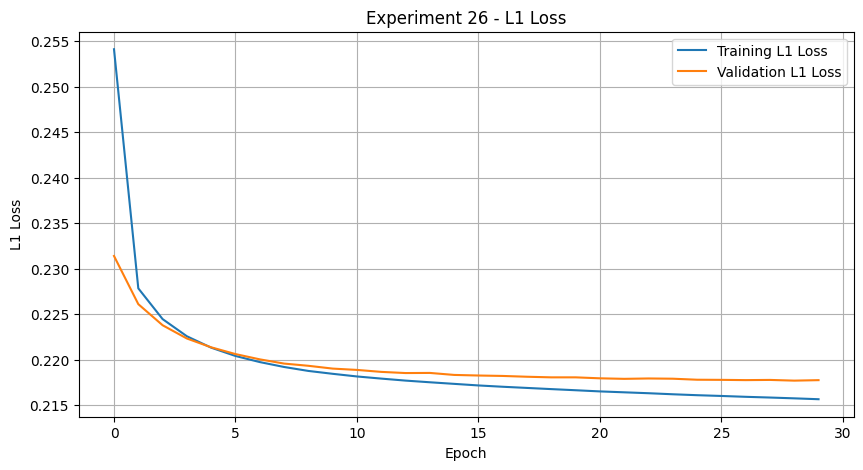

In [155]:
# EXPERIMENT 26 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp26_train_losses,
    label="Training L1 Loss"
)

plt.plot(
    exp26_val_losses,
    label="Validation L1 Loss"
)

plt.title("Experiment 26 - L1 Loss")
plt.xlabel("Epoch")
plt.ylabel("L1 Loss")

plt.legend()
plt.grid(True)

plt.show()

In [156]:
# EXPERIMENT 27 - HUBER LOSS (DELTA = 0.5)
# Hidden Layers = 2
# Neurons = 64

# 1. Create a fresh DNN model

class Experiment27Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp27_model = Experiment27Model(input_size=315)

print(exp27_model)

Experiment27Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [157]:
# EXPERIMENT 27 - TRAINING SETUP

# Create DataLoader

exp27_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# Define Huber loss function

exp27_criterion = nn.HuberLoss(delta=0.5)

# Define optimizer

exp27_optimizer = optim.Adam(
    exp27_model.parameters(),
    lr=0.00001
)

# Set number of epochs

exp27_epochs = 30

# Store training and validation losses

exp27_train_losses = []
exp27_val_losses = []

print("Experiment 27 training setup completed!")

Experiment 27 training setup completed!


In [158]:
# EXPERIMENT 27 - START TRAINING

import time

exp27_start_time = time.time()

for epoch in range(exp27_epochs):

    exp27_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp27_train_loader:

        predictions = exp27_model(X_batch)

        loss = exp27_criterion(predictions, y_batch)

        exp27_optimizer.zero_grad()
        loss.backward()
        exp27_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp27_model.eval()

    with torch.no_grad():

        val_predictions = exp27_model(X_val_tensor)

        val_loss = exp27_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp27_train_losses.append(train_loss)
    exp27_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp27_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp27_training_time = time.time() - exp27_start_time

print(f"Training time: {exp27_training_time:.2f} seconds")

# Display final results

print("Experiment 27 completed!")

print("Final training Huber Loss:", exp27_train_losses[-1])
print("Final validation Huber Loss:", exp27_val_losses[-1])

print(
    "Training time:",
    round(exp27_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.0710, Val Loss: 0.0631
Epoch [2/30], Train Loss: 0.0622, Val Loss: 0.0616
Epoch [3/30], Train Loss: 0.0613, Val Loss: 0.0610
Epoch [4/30], Train Loss: 0.0608, Val Loss: 0.0606
Epoch [5/30], Train Loss: 0.0605, Val Loss: 0.0604
Epoch [6/30], Train Loss: 0.0602, Val Loss: 0.0602
Epoch [7/30], Train Loss: 0.0601, Val Loss: 0.0600
Epoch [8/30], Train Loss: 0.0599, Val Loss: 0.0599
Epoch [9/30], Train Loss: 0.0598, Val Loss: 0.0598
Epoch [10/30], Train Loss: 0.0597, Val Loss: 0.0598
Epoch [11/30], Train Loss: 0.0596, Val Loss: 0.0597
Epoch [12/30], Train Loss: 0.0595, Val Loss: 0.0597
Epoch [13/30], Train Loss: 0.0594, Val Loss: 0.0596
Epoch [14/30], Train Loss: 0.0594, Val Loss: 0.0596
Epoch [15/30], Train Loss: 0.0593, Val Loss: 0.0596
Epoch [16/30], Train Loss: 0.0593, Val Loss: 0.0595
Epoch [17/30], Train Loss: 0.0592, Val Loss: 0.0595
Epoch [18/30], Train Loss: 0.0592, Val Loss: 0.0595
Epoch [19/30], Train Loss: 0.0592, Val Loss: 0.0595
Epoch [20/30], Train 

In [159]:
# EXPERIMENT 27 - EVALUATE MODEL

exp27_model.eval()

with torch.no_grad():

    exp27_val_scaled = exp27_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp27_val_predictions = target_scaler.inverse_transform(
        exp27_val_scaled
    )

    # Calculate validation MSE

    exp27_val_mse = mean_squared_error(
        y_val,
        exp27_val_predictions
    )

print("Experiment 27 Validation MSE:", exp27_val_mse)

Experiment 27 Validation MSE: 4586736640.0


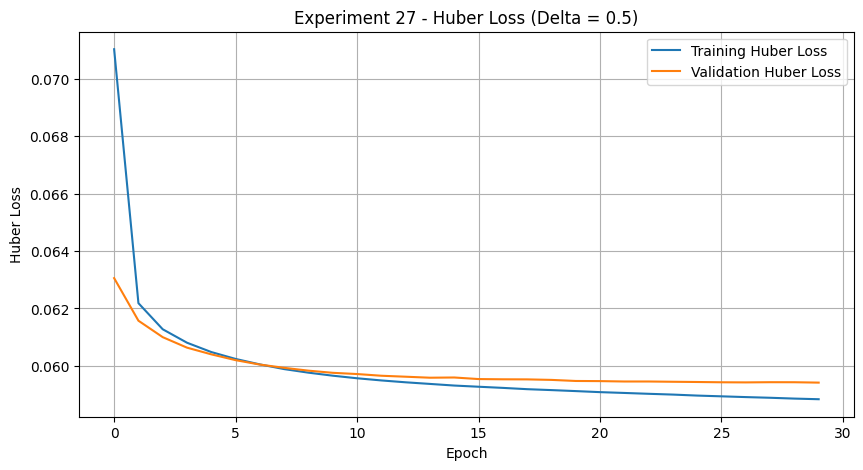

In [160]:
# EXPERIMENT 27 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp27_train_losses,
    label="Training Huber Loss"
)

plt.plot(
    exp27_val_losses,
    label="Validation Huber Loss"
)

plt.title("Experiment 27 - Huber Loss (Delta = 0.5)")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")

plt.legend()
plt.grid(True)

plt.show()

In [161]:
# EXPERIMENT 28 - HUBER LOSS (DELTA = 1.0)

# 1. Create a fresh DNN model

class Experiment28Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp28_model = Experiment28Model(input_size=315)

print(exp28_model)

Experiment28Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [162]:
# EXPERIMENT 28 - TRAINING SETUP

# Create DataLoader

exp28_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# Define Huber loss function

exp28_criterion = nn.HuberLoss(delta=1.0)

# Define optimizer

exp28_optimizer = optim.Adam(
    exp28_model.parameters(),
    lr=0.00001
)

# Number of epochs

exp28_epochs = 30

# Store training and validation losses

exp28_train_losses = []
exp28_val_losses = []

print("Experiment 28 training setup completed!")

Experiment 28 training setup completed!


In [163]:
# EXPERIMENT 28 - START TRAINING

import time

exp28_start_time = time.time()

for epoch in range(exp28_epochs):

    exp28_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp28_train_loader:

        predictions = exp28_model(X_batch)

        loss = exp28_criterion(predictions, y_batch)

        exp28_optimizer.zero_grad()
        loss.backward()
        exp28_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp28_model.eval()

    with torch.no_grad():

        val_predictions = exp28_model(X_val_tensor)

        val_loss = exp28_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp28_train_losses.append(train_loss)
    exp28_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp28_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp28_training_time = time.time() - exp28_start_time

print(f"Training time: {exp28_training_time:.2f} seconds")

# Display final results

print("Experiment 28 completed!")

print("Final training Huber Loss:", exp28_train_losses[-1])
print("Final validation Huber Loss:", exp28_val_losses[-1])

print(
    "Training time:",
    round(exp28_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.1078, Val Loss: 0.0981
Epoch [2/30], Train Loss: 0.0970, Val Loss: 0.0955
Epoch [3/30], Train Loss: 0.0953, Val Loss: 0.0945
Epoch [4/30], Train Loss: 0.0944, Val Loss: 0.0939
Epoch [5/30], Train Loss: 0.0939, Val Loss: 0.0935
Epoch [6/30], Train Loss: 0.0935, Val Loss: 0.0932
Epoch [7/30], Train Loss: 0.0932, Val Loss: 0.0930
Epoch [8/30], Train Loss: 0.0930, Val Loss: 0.0929
Epoch [9/30], Train Loss: 0.0929, Val Loss: 0.0928
Epoch [10/30], Train Loss: 0.0927, Val Loss: 0.0928
Epoch [11/30], Train Loss: 0.0926, Val Loss: 0.0927
Epoch [12/30], Train Loss: 0.0925, Val Loss: 0.0926
Epoch [13/30], Train Loss: 0.0924, Val Loss: 0.0926
Epoch [14/30], Train Loss: 0.0923, Val Loss: 0.0926
Epoch [15/30], Train Loss: 0.0923, Val Loss: 0.0925
Epoch [16/30], Train Loss: 0.0922, Val Loss: 0.0925
Epoch [17/30], Train Loss: 0.0921, Val Loss: 0.0924
Epoch [18/30], Train Loss: 0.0921, Val Loss: 0.0924
Epoch [19/30], Train Loss: 0.0920, Val Loss: 0.0924
Epoch [20/30], Train 

In [164]:
# EXPERIMENT 28 - EVALUATE MODEL

exp28_model.eval()

with torch.no_grad():

    exp28_val_scaled = exp28_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp28_val_predictions = target_scaler.inverse_transform(
        exp28_val_scaled
    )

    # Calculate validation MSE

    exp28_val_mse = mean_squared_error(
        y_val,
        exp28_val_predictions
    )

print("Experiment 28 Validation MSE:", exp28_val_mse)

Experiment 28 Validation MSE: 4542418944.0


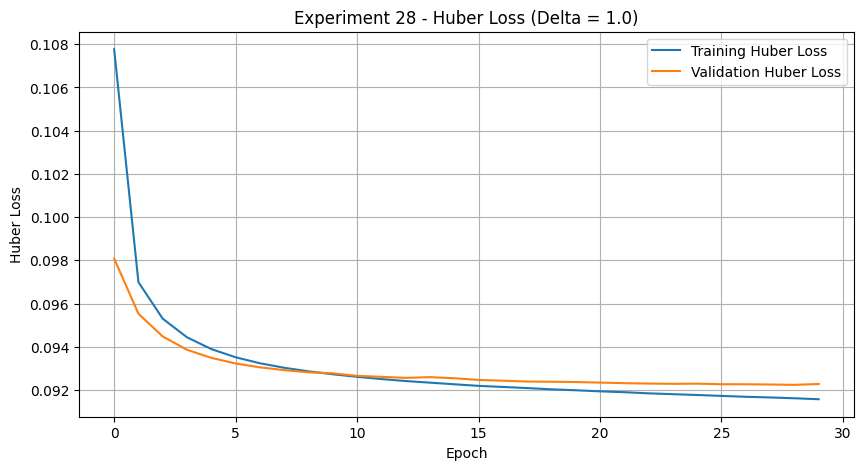

In [165]:
# EXPERIMENT 28 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp28_train_losses,
    label="Training Huber Loss"
)

plt.plot(
    exp28_val_losses,
    label="Validation Huber Loss"
)

plt.title("Experiment 28 - Huber Loss (Delta = 1.0)")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")

plt.legend()
plt.grid(True)

plt.show()

In [166]:
# EXPERIMENT 29 - HUBER LOSS (DELTA = 2.0)

# 1. Create a fresh DNN model

class Experiment29Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp29_model = Experiment29Model(input_size=315)

print(exp29_model)

Experiment29Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [167]:
# EXPERIMENT 29 - TRAINING SETUP

# Create DataLoader

exp29_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# Define Huber loss function

exp29_criterion = nn.HuberLoss(delta=2.0)

# Define optimizer

exp29_optimizer = optim.Adam(
    exp29_model.parameters(),
    lr=0.00001
)

# Number of epochs

exp29_epochs = 30

# Store training and validation losses

exp29_train_losses = []
exp29_val_losses = []

print("Experiment 29 training setup completed!")

Experiment 29 training setup completed!


In [168]:
# EXPERIMENT 29 - START TRAINING

import time

exp29_start_time = time.time()

for epoch in range(exp29_epochs):

    exp29_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp29_train_loader:

        predictions = exp29_model(X_batch)

        loss = exp29_criterion(predictions, y_batch)

        exp29_optimizer.zero_grad()
        loss.backward()
        exp29_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp29_model.eval()

    with torch.no_grad():

        val_predictions = exp29_model(X_val_tensor)

        val_loss = exp29_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp29_train_losses.append(train_loss)
    exp29_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp29_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp29_training_time = time.time() - exp29_start_time

print(f"Training time: {exp29_training_time:.2f} seconds")

# Display final results

print("Experiment 29 completed!")

print("Final training Huber Loss:", exp29_train_losses[-1])
print("Final validation Huber Loss:", exp29_val_losses[-1])

print(
    "Training time:",
    round(exp29_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.1589, Val Loss: 0.1455
Epoch [2/30], Train Loss: 0.1452, Val Loss: 0.1408
Epoch [3/30], Train Loss: 0.1421, Val Loss: 0.1389
Epoch [4/30], Train Loss: 0.1405, Val Loss: 0.1377
Epoch [5/30], Train Loss: 0.1395, Val Loss: 0.1370
Epoch [6/30], Train Loss: 0.1387, Val Loss: 0.1365
Epoch [7/30], Train Loss: 0.1382, Val Loss: 0.1362
Epoch [8/30], Train Loss: 0.1379, Val Loss: 0.1360
Epoch [9/30], Train Loss: 0.1376, Val Loss: 0.1359
Epoch [10/30], Train Loss: 0.1374, Val Loss: 0.1358
Epoch [11/30], Train Loss: 0.1373, Val Loss: 0.1358
Epoch [12/30], Train Loss: 0.1372, Val Loss: 0.1357
Epoch [13/30], Train Loss: 0.1371, Val Loss: 0.1358
Epoch [14/30], Train Loss: 0.1370, Val Loss: 0.1356
Epoch [15/30], Train Loss: 0.1369, Val Loss: 0.1356
Epoch [16/30], Train Loss: 0.1368, Val Loss: 0.1356
Epoch [17/30], Train Loss: 0.1367, Val Loss: 0.1356
Epoch [18/30], Train Loss: 0.1367, Val Loss: 0.1355
Epoch [19/30], Train Loss: 0.1366, Val Loss: 0.1357
Epoch [20/30], Train 

In [169]:
# EXPERIMENT 29 - EVALUATE MODEL

exp29_model.eval()

with torch.no_grad():

    exp29_val_scaled = exp29_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp29_val_predictions = target_scaler.inverse_transform(
        exp29_val_scaled
    )

    # Calculate validation MSE

    exp29_val_mse = mean_squared_error(
        y_val,
        exp29_val_predictions
    )

print("Experiment 29 Validation MSE:", exp29_val_mse)

Experiment 29 Validation MSE: 4517514752.0


In [ ]:
# EXPERIMENT 29 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp29_train_losses,
    label="Training Huber Loss"
)

plt.plot(
    exp29_val_losses,
    label="Validation Huber Loss"
)

plt.title("Experiment 29 - Huber Loss (Delta = 2.0)")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")

plt.legend()
plt.grid(True)

plt.show()

In [170]:
# EXPERIMENT 30 - HUBER LOSS (DELTA = 0.25)

# 1. Create a fresh DNN model

class Experiment30Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp30_model = Experiment30Model(input_size=315)

print(exp30_model)

Experiment30Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [171]:
# EXPERIMENT 30 - TRAINING SETUP

# Create DataLoader

exp30_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

# Define Huber loss function

exp30_criterion = nn.HuberLoss(delta=0.25)

# Define optimizer

exp30_optimizer = optim.Adam(
    exp30_model.parameters(),
    lr=0.00001
)

# Number of epochs

exp30_epochs = 30

# Store training and validation losses

exp30_train_losses = []
exp30_val_losses = []

print("Experiment 30 training setup completed!")

Experiment 30 training setup completed!


In [172]:
# EXPERIMENT 30 - START TRAINING

import time

exp30_start_time = time.time()

for epoch in range(exp30_epochs):

    exp30_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp30_train_loader:

        predictions = exp30_model(X_batch)

        loss = exp30_criterion(predictions, y_batch)

        exp30_optimizer.zero_grad()
        loss.backward()
        exp30_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp30_model.eval()

    with torch.no_grad():

        val_predictions = exp30_model(X_val_tensor)

        val_loss = exp30_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp30_train_losses.append(train_loss)
    exp30_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp30_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp30_training_time = time.time() - exp30_start_time

print(f"Training time: {exp30_training_time:.2f} seconds")

# Display final results

print("Experiment 30 completed!")

print("Final training Huber Loss:", exp30_train_losses[-1])
print("Final validation Huber Loss:", exp30_val_losses[-1])

print(
    "Training time:",
    round(exp30_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.0439, Val Loss: 0.0393
Epoch [2/30], Train Loss: 0.0386, Val Loss: 0.0382
Epoch [3/30], Train Loss: 0.0380, Val Loss: 0.0378
Epoch [4/30], Train Loss: 0.0376, Val Loss: 0.0375
Epoch [5/30], Train Loss: 0.0374, Val Loss: 0.0373
Epoch [6/30], Train Loss: 0.0372, Val Loss: 0.0372
Epoch [7/30], Train Loss: 0.0371, Val Loss: 0.0371
Epoch [8/30], Train Loss: 0.0370, Val Loss: 0.0370
Epoch [9/30], Train Loss: 0.0369, Val Loss: 0.0370
Epoch [10/30], Train Loss: 0.0369, Val Loss: 0.0370
Epoch [11/30], Train Loss: 0.0368, Val Loss: 0.0369
Epoch [12/30], Train Loss: 0.0368, Val Loss: 0.0369
Epoch [13/30], Train Loss: 0.0367, Val Loss: 0.0369
Epoch [14/30], Train Loss: 0.0367, Val Loss: 0.0368
Epoch [15/30], Train Loss: 0.0367, Val Loss: 0.0368
Epoch [16/30], Train Loss: 0.0366, Val Loss: 0.0368
Epoch [17/30], Train Loss: 0.0366, Val Loss: 0.0368
Epoch [18/30], Train Loss: 0.0366, Val Loss: 0.0368
Epoch [19/30], Train Loss: 0.0366, Val Loss: 0.0368
Epoch [20/30], Train 

In [173]:
# EXPERIMENT 30 - EVALUATE MODEL

exp30_model.eval()

with torch.no_grad():

    exp30_val_scaled = exp30_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp30_val_predictions = target_scaler.inverse_transform(
        exp30_val_scaled
    )

    # Calculate validation MSE

    exp30_val_mse = mean_squared_error(
        y_val,
        exp30_val_predictions
    )

print("Experiment 30 Validation MSE:", exp30_val_mse)

Experiment 30 Validation MSE: 4622107648.0


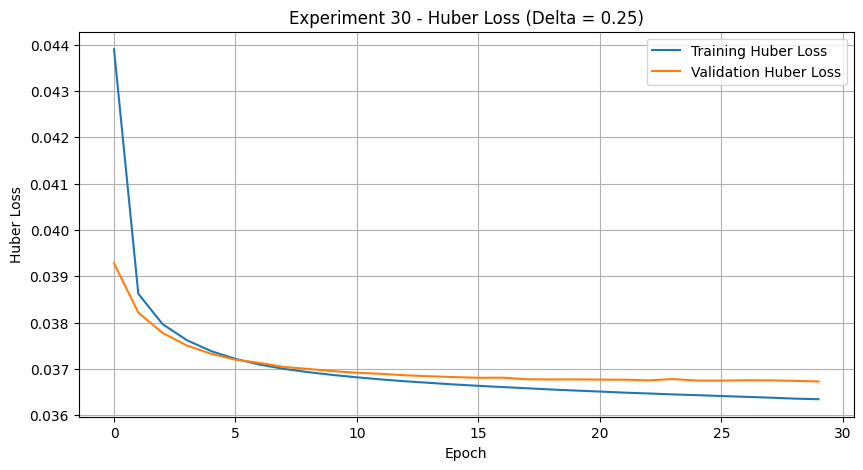

In [174]:
# EXPERIMENT 30 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp30_train_losses,
    label="Training Huber Loss"
)

plt.plot(
    exp30_val_losses,
    label="Validation Huber Loss"
)

plt.title("Experiment 30 - Huber Loss (Delta = 0.25)")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")

plt.legend()
plt.grid(True)

plt.show()

In [175]:
# EXPERIMENT 31 - BATCH SIZE 64

# 1. Create a fresh DNN model

class Experiment31Model(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model

exp31_model = Experiment31Model(input_size=315)

print(exp31_model)

Experiment31Model(
  (network): Sequential(
    (0): Linear(in_features=315, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [176]:
# EXPERIMENT 31 - TRAINING SETUP

# Create DataLoader

exp31_train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# Define loss function

exp31_criterion = nn.HuberLoss(delta=0.25)

# Define optimizer

exp31_optimizer = optim.Adam(
    exp31_model.parameters(),
    lr=0.00001
)

# Number of epochs

exp31_epochs = 30

# Store training and validation losses

exp31_train_losses = []
exp31_val_losses = []

print("Experiment 31 training setup completed!")

Experiment 31 training setup completed!


In [177]:
# EXPERIMENT 31 - START TRAINING

import time

exp31_start_time = time.time()

for epoch in range(exp31_epochs):

    exp31_model.train()
    total_train_loss = 0

    for X_batch, y_batch in exp31_train_loader:

        predictions = exp31_model(X_batch)

        loss = exp31_criterion(predictions, y_batch)

        exp31_optimizer.zero_grad()
        loss.backward()
        exp31_optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    # Calculate average training loss

    train_loss = total_train_loss / len(train_dataset)

    # Validation

    exp31_model.eval()

    with torch.no_grad():

        val_predictions = exp31_model(X_val_tensor)

        val_loss = exp31_criterion(
            val_predictions,
            y_val_tensor
        ).item()

    # Save losses

    exp31_train_losses.append(train_loss)
    exp31_val_losses.append(val_loss)

    # Display results

    print(
        f"Epoch [{epoch+1}/{exp31_epochs}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

# Calculate training time

exp31_training_time = time.time() - exp31_start_time

print(f"Training time: {exp31_training_time:.2f} seconds")

# Display final results

print("Experiment 31 completed!")

print("Final training loss:", exp31_train_losses[-1])
print("Final validation loss:", exp31_val_losses[-1])

print(
    "Training time:",
    round(exp31_training_time, 2),
    "seconds"
)

Epoch [1/30], Train Loss: 0.0487, Val Loss: 0.0418
Epoch [2/30], Train Loss: 0.0404, Val Loss: 0.0396
Epoch [3/30], Train Loss: 0.0390, Val Loss: 0.0387
Epoch [4/30], Train Loss: 0.0384, Val Loss: 0.0383
Epoch [5/30], Train Loss: 0.0381, Val Loss: 0.0380
Epoch [6/30], Train Loss: 0.0378, Val Loss: 0.0378
Epoch [7/30], Train Loss: 0.0376, Val Loss: 0.0376
Epoch [8/30], Train Loss: 0.0375, Val Loss: 0.0375
Epoch [9/30], Train Loss: 0.0374, Val Loss: 0.0374
Epoch [10/30], Train Loss: 0.0373, Val Loss: 0.0373
Epoch [11/30], Train Loss: 0.0372, Val Loss: 0.0372
Epoch [12/30], Train Loss: 0.0371, Val Loss: 0.0372
Epoch [13/30], Train Loss: 0.0371, Val Loss: 0.0371
Epoch [14/30], Train Loss: 0.0370, Val Loss: 0.0371
Epoch [15/30], Train Loss: 0.0370, Val Loss: 0.0370
Epoch [16/30], Train Loss: 0.0369, Val Loss: 0.0370
Epoch [17/30], Train Loss: 0.0369, Val Loss: 0.0370
Epoch [18/30], Train Loss: 0.0369, Val Loss: 0.0370
Epoch [19/30], Train Loss: 0.0368, Val Loss: 0.0369
Epoch [20/30], Train 

In [178]:
# EXPERIMENT 31 - EVALUATE MODEL

exp31_model.eval()

with torch.no_grad():

    exp31_val_scaled = exp31_model(X_val_tensor).numpy()

    # Convert predictions to original price scale

    exp31_val_predictions = target_scaler.inverse_transform(
        exp31_val_scaled
    )

    # Calculate validation MSE

    exp31_val_mse = mean_squared_error(
        y_val,
        exp31_val_predictions
    )

print("Experiment 31 Validation MSE:", exp31_val_mse)

Experiment 31 Validation MSE: 4637480448.0


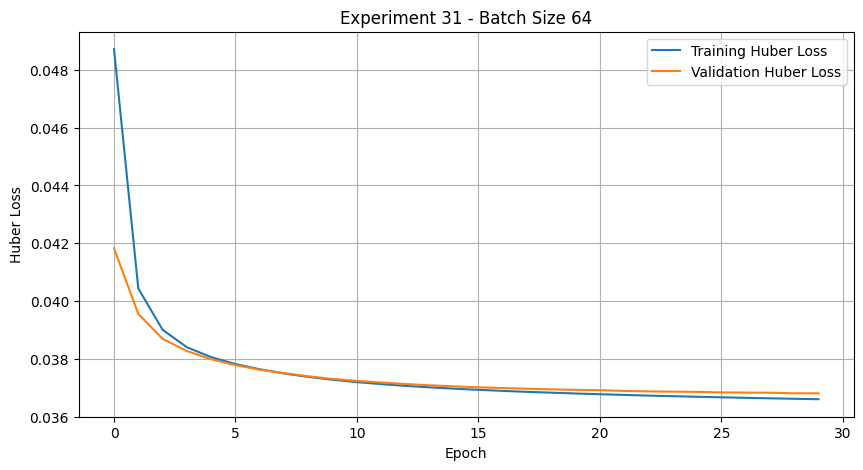

In [179]:
# EXPERIMENT 31 - PLOT RESULTS

plt.figure(figsize=(10, 5))

plt.plot(
    exp31_train_losses,
    label="Training Huber Loss"
)

plt.plot(
    exp31_val_losses,
    label="Validation Huber Loss"
)

plt.title("Experiment 31 - Batch Size 64")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")

plt.legend()
plt.grid(True)

plt.show()

In [181]:
#final model experiment 23
best_model = exp23_model
#evaluate on test set
best_model.eval()
with torch.no_grad():
    test_predictions = best_model(X_test_tensor).numpy()
    #covert prediction back to original price scale
    test_predictions = target_scaler.inverse_transform(test_predictions)
#calculate test MSE
test_mse = mean_squared_error(y_test, test_predictions)

print("final model evaluation")
print("_________________________")
print("selected model: experiment 23")
print("validation MSE:", exp23_val_mse)
print("test MSE:", test_mse)

final model evaluation
_________________________
selected model: experiment 23
validation MSE: 4497785856.0
test MSE: 4333414912.0
